# Calibrating the IFT cloud mask and ice/water mask

The IFT cloud mask aims to balance identification of opaque clouds with allowing thin clouds to be processed. This is done on the basis of Band 7 and Band 2 in the false color images. There are 5 continuous parameters. Additionally there are morphological functions for cleanup that can be adjusted.

## Algorithm 1
1. $A \gets B_7 > \tau_0$
2. $B \gets B_7 < \tau_{B7} \text{ and } B_2 > \tau_{B2}$
3. $C \gets B_7 < \tau_{r1}(B_2 - \tau_{r2})$
4. $M \gets A \setminus (B \cap C)$

This function is defined in Lopez-Acosta et al. 2019, with somewhat ambiguous wording. Last year, I worked on a version of this in which I updated the settings in the mask, then added some post-processing cleanup. The description in the paper wasn't satisfying to me. The calibration remained pretty ad-hoc. The original fitting was done in Python, which is weird for a Julia-based algorithm. My aim is to find something that is cleaner conceptually that we can run in Julia.

## Algorithm 1a
1. Carry out Algorithm 1 with updated parameters
2. Remove speckle with morphological opening
3. Fill holes

This version is better, but still the shape of the curve doesn't really match the data very well. One particular challenge is the "thin cloud" section. We just don't have much data there.

## Algorithm 2
1. Select $B_7 > \tau_{b7} \; \& \; B_2 > \tau_{b2}$
2. Remove speckle with morphological opening
3. Expand mask by morphological dilation
4. Object-based mask extension
   1. Invert mask
   2. Label components
   3. Remove components smaller than the min floe size
   4. Remove components with low contrast

We can do pixel-wise evaluation for whether sea ice floes get covered, potentially. Then, we apply the adaptive histogram approach to the ice/water discrimination problem. 

In [2]:
using Pkg
# Pkg.activate("../scripts/calval/")
Pkg.activate("calval")
# Pkg.instantiate()
using CairoMakie
using CSV
using DataFrames
using Dates
using FHist
using IceFloeTracker
using Interpolations
using Images
using Random
using StatsBase

# include("../scripts/cloud_ice_masks_functions.jl")

  Activating project at `~/Documents/research/calval_tgrs/notebooks/calval`


# Data
We select a random sample of images, stratified by the presence fo sea ice, and set aside a set for verification. We also read in a set of cloud fraction estimates from the MODIS 5 km product.

### Grouping pixels
* Cloud - MODIS clouds > 20%. No visible sea ice, mask the landfast ice.
* Sea Ice (Clear Sky) - Labeled Ice Floe + Clouds < 20%.
* Sea Ice (Thin Clouds) - Labeled Ice Floe + Clouds > 20% + Obscuration None or Light
* Sea Ice (Thick Clouds) - Labeled Ice Floe + Clouds > 20%
* Water - Labeled water

In [3]:
dataset = Watkins2026Dataset(ref="main")
# Add a column to indicate whether water samples have been generated yet
water_sample_files = readdir("../../ice_floe_validation_dataset/data/validation_dataset/binary_water_samples/")
water_sample_files = filter(r -> r != ".DS_Store", water_sample_files)
water_sample_cases = parse.(Int64, first.(split.(water_sample_files, "-")))
dataset.info[:, :water_sample] = (x -> x ∈ water_sample_cases).(dataset.info.case_number)
nothing

In [3]:
#### Run this to re-draw the sample ####
# Generate stratified train/test samples
min_floe_size = 64
fraction = 2/3
seed = 20
rng = Random.default_rng(seed)
df = dataset.info
max_floe_sizes = Int64.(coalesce.(df[!, :maximum_floe_size], 0));
df[:, :ice_floes] = max_floe_sizes .> min_floe_size

gdf = groupby(df[df.satellite .== "aqua",:], :ice_floes)
train_data = []
test_data = []
for group in gdf
    n = round(Int64, fraction * nrow(group))
    idx_all = 1:nrow(group)
    train_idx = StatsBase.sample(rng, idx_all, n; replace=false, ordered=true)
    test_idx = [x for x ∈ idx_all if x ∉ train_idx]
    push!(train_data, group[train_idx, :])
    push!(test_data, group[test_idx, :])    
end
train_df = reduce(vcat, train_data)
test_df = reduce(vcat, test_data);
df[:, :train] = [x ∈ train_df.case_number for x in df.case_number]
satellite = StatsBase.sample(["aqua", "terra"], maximum(df.case_number); replace=true)
training = [x ∈ train_df.case_number for x in df.case_number]

# Now add a Boolean column to the dataset object, so we can filter on it.
dataset.info[:, :training_sample] .= [
    (s == satellite[cn]) && training[cn] for (cn, s) in zip(dataset.info.case_number, dataset.info.satellite)
        ];
dataset.info[:, :testing_sample] .= [
    (s == satellite[cn]) && !training[cn] for (cn, s) in zip(dataset.info.case_number, dataset.info.satellite)
        ];
# Now: get the training and testing data, single image per case.
train_cases = filter(c -> c.training_sample, dataset) 
test_cases = filter(c -> c.testing_sample, dataset);

# Uncomment to re-draw sample and save
# save("../data/train_test_split.csv", dataset.info)

In [9]:
#### Run this to use the previously defined test/train split ####
prior_data = DataFrame(CSV.File("../data/train_test_split.csv"))
dataset.info[:, :training_sample] = prior_data[:, :training_sample]
dataset.info[:, :testing_sample] = prior_data[:, :testing_sample]
train_cases = filter(c -> c.training_sample, dataset) 
test_cases = filter(c -> c.testing_sample, dataset);

## Load images: Training

In addition to the validation dataset images, we load the numeric translation of the color 5 km MODIS cloud fraction snapshots, and we replace missing images with blank images.

In [10]:
tc_imgs = modis_truecolor.(train_cases)
fc_imgs = modis_falsecolor.(train_cases)
sea_ice_floes = validated_binary_floes.(train_cases)
land_masks = modis_landmask.(train_cases) .|> r -> r .> 0; # Load land masks and convert to binary
landfast_ice_masks = validated_binary_landfast.(train_cases);

# Add column with cloud fraction path
cloudfrac_loc = "../data/cloudfraction_numeric/"
transform!(train_cases.info, [:case_number, :region, :satellite, :start_date] => ByRow((cn, r, s, d) ->
    join([lpad(cn, 3, "0"), r, Dates.format(d, "yyyymmdd"), s, "cloudfraction.csv"], "-")) => :cloudfrac_file)

# Load numeric cloud fraction data
modis_cloudfrac = load.(joinpath.(cloudfrac_loc, train_cases.info[:, :cloudfrac_file])) .|> 
                            DataFrame .|> r -> Array(r[:, 2:end]);

# Computes the average of un-masked data
function masked_mean(data, mask)
    d = vec(data)
    m = vec(mask) .> 0
    return mean(d[.!m])
end

function fill_missing!(cases; template=Gray.(zeros(Bool, (400, 400))))
    for (idx, img) in enumerate(cases)
        if isnothing(img)
            cases[idx] = template
        end
    end
end

function validated_binary_water(case::Case)
    info(case).water_sample == 0 && return nothing
    (; case_number, region, date, satellite) = IceFloeTracker.Data._filename_parts(case)
    file = "data/validation_dataset/binary_water_samples/$(case_number)-$(region)-$(date)-$(satellite)-binary_water_samples.png"
    img = file |> case.loader |> load |> binarize_mask .|> Gray
    return img
end

fill_missing!(landfast_ice_masks)
fill_missing!(sea_ice_floes)

# Generate binary MODIS mask with 75% threshold
modis_cloud_masks = [m .> 75 for (m, f) in zip(modis_cloudfrac, fc_imgs)]

# compute MODIS estimated cloud fraction for all pixels
train_cases.info[:, :lookup_index] .= 1:length(train_cases) # This gives us the index for the data loaders
train_cases.info[:, "cloud_fraction_modis"] = round.(mean.(modis_cloudfrac) ./ 100, digits=2);
train_cases.info[:, "cloud_fraction_modis_ocean"] = round.(masked_mean.(modis_cloudfrac, land_masks)./ 100, digits=2);

# Illustration of cloud mask operation

Question here: where do the middle cloud portions fit on the histogram? They can sometimes get left out of the cloud mask.

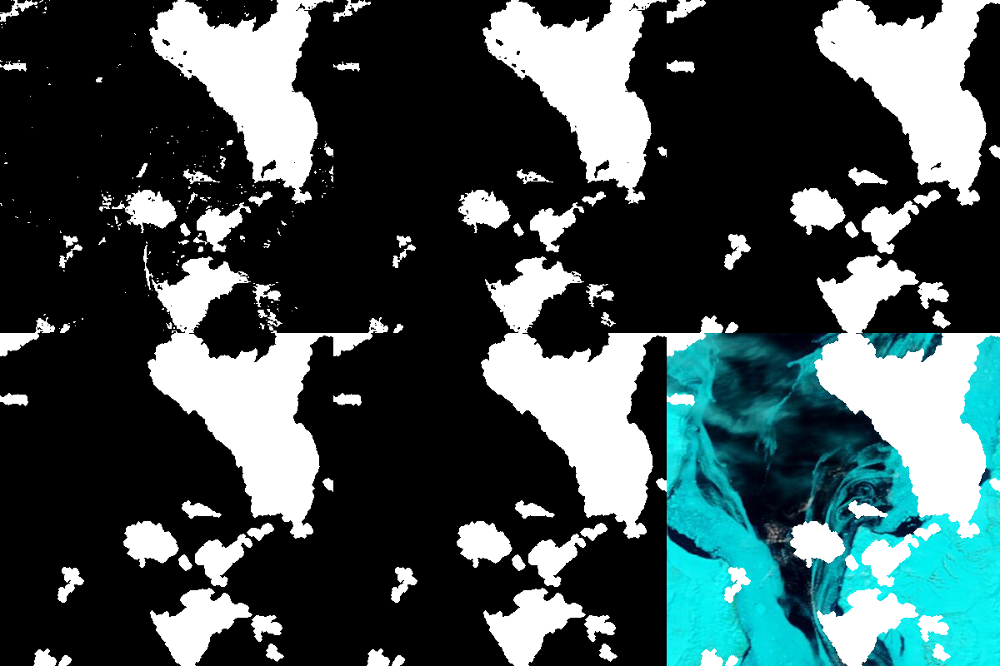

In [27]:
fc_img = fc_imgs[115]
opening_strel=strel_disk(3)
dilation_strel=strel_disk(2)
min_hole_size=300
min_contrast=0.2
max_fill_size=10_000

tau_b2 = 0.34
tau_b7 = 0.16
b2 = green.(fc_img)
b7 = red.(fc_img)
init_mask = (b2 .> tau_b2) .&& (b7 .> tau_b7)
apply_landmask!(init_mask, land_masks[11])

# remove speckle
markers = opening(init_mask, opening_strel)
stage_1_mask = mreconstruct(dilate, markers, init_mask, strel_diamond((3, 3)))

# expand mask
stage_2_mask = dilate(stage_1_mask, dilation_strel)

# label blank components for object-based methods (background == clouds)
labels_init = label_components(.!stage_2_mask)
labels = deepcopy(labels_init)

remove_small_segments!(labels, min_hole_size)

low_contrast_removed = deepcopy(labels)
remove_low_contrast_segments!(low_contrast_removed, b2, min_contrast, max_fill_size)

mosaicview(Gray.(init_mask), Gray.(stage_1_mask), Gray.(stage_2_mask), Gray.(labels .== 0), Gray.(low_contrast_removed .== 0),
    fc_img .* (low_contrast_removed .> 0), nrow=2, rowmajor=true)

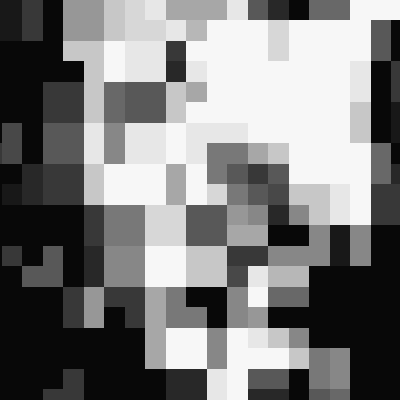

In [35]:
Gray.(modis_cloudfrac[115] ./ 100)

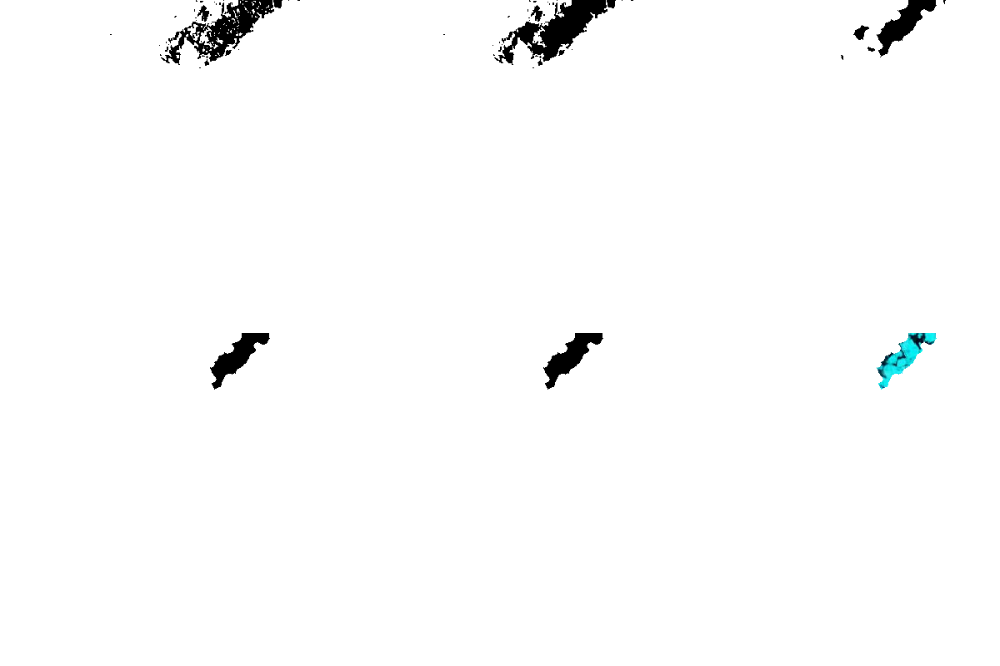

In [17]:
fc_img = fc_imgs[10]
opening_strel=strel_disk(3)
dilation_strel=strel_disk(4)
min_hole_size=300
min_contrast=0.2
max_fill_size=10_000

tau_b2 = 0.34
tau_b7 = 0.15
b2 = green.(fc_img)
b7 = red.(fc_img)
init_mask = (b2 .> tau_b2) .&& (b7 .> tau_b7)
apply_landmask!(init_mask, land_masks[11])

# remove speckle
markers = opening(init_mask, opening_strel)
stage_1_mask = mreconstruct(dilate, markers, init_mask, strel_diamond((3, 3)))

# expand mask
stage_2_mask = dilate(stage_1_mask, dilation_strel)

# label blank components for object-based methods (background == clouds)
labels_init = label_components(.!stage_2_mask)
labels = deepcopy(labels_init)

remove_small_segments!(labels, min_hole_size)

low_contrast_removed = deepcopy(labels)
min_contrast = 0.4
remove_low_contrast_segments!(low_contrast_removed, b2, min_contrast, max_fill_size)

mosaicview(Gray.(init_mask), Gray.(stage_1_mask), Gray.(stage_2_mask), Gray.(labels .== 0), Gray.(low_contrast_removed .== 0),
    fc_img .* (low_contrast_removed .> 0), nrow=2, rowmajor=true)

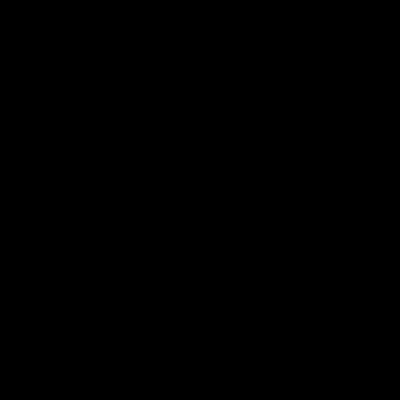

In [18]:
Gray.(CloudMask(fc_imgs[11]))

In [19]:
# Show falsecolor iamges
# mosaicview(fc_imgs[idx], nrow=5, npad=10, fillvalue=RGBA(0,0,0,0))

In [20]:
# Show ice under cloud
# mosaicview(visualize_ice_under_cloud.(sea_ice_floes[idx], modis_cloud_masks[idx], land_masks[idx]), nrow=5, npad=10, fillvalue=RGBA(0,0,0,0))

# Visualize histograms

B2 quantiles[0.25098039215686274, 0.6705882352941176, 0.8, 0.8705882352941177, 0.9411764705882353]
B7 quantiles[0.023529411764705882, 0.3058823529411765, 0.4980392156862745, 0.6313725490196078, 0.7098039215686275]


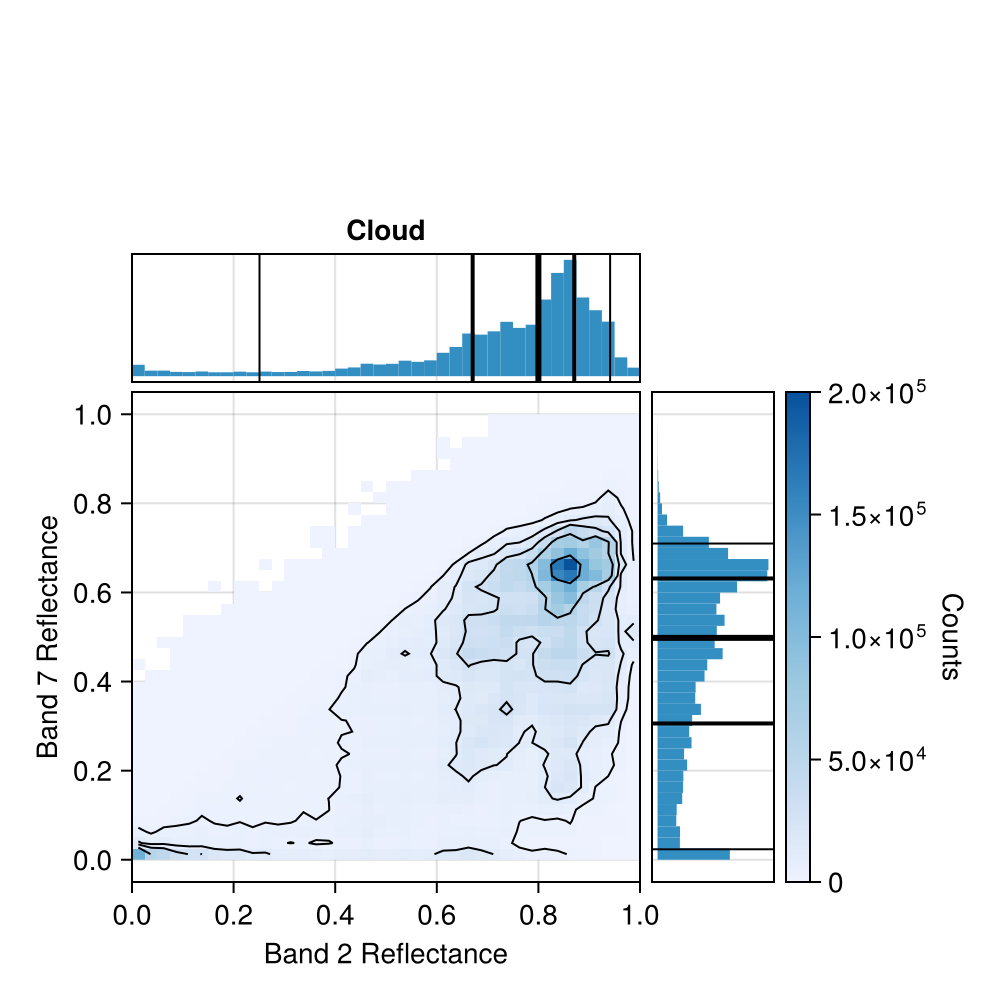

In [21]:
### Cloudy cases
modis_threshold = 75
b2_clouds = []
b7_clouds = []
b2_non_clouds = []
b1_non_clouds = []
b7_non_clouds = []
for idx in train_cases.info.lookup_index
    clouds = vec(modis_cloudfrac[idx] .> modis_threshold)
    land = vec(land_masks[idx] .> 0)
    b2 = green.(fc_imgs[idx])
    b7 = red.(fc_imgs[idx])
    b1 = vec(blue.(fc_imgs[idx]))
    selection = clouds .&& .! land # .&& (b1 .> 0.2)
    push!(b2_clouds, Float64.(b2[selection]))
    push!(b7_clouds, Float64.(b7[selection]))

    selection = .! clouds .&& .! land
    push!(b2_non_clouds, Float64.(b2[selection]))
    push!(b7_non_clouds, Float64.(b7[selection]))
    push!(b1_non_clouds, Float64.(b1[selection]))
    
end
b2_clouds = vcat(b2_clouds...)
b7_clouds = vcat(b7_clouds...)
b2_non_clouds = vcat(b2_non_clouds...)
b7_non_clouds = vcat(b7_non_clouds...)
b1_non_clouds = vcat(b1_non_clouds...)

fig = Figure(size=(500,500))

#### Cloudy pixels

bins = 0:0.025:1
h2 = Hist1D(b2_clouds; binedges=bins);
h7 = Hist1D(b7_clouds, binedges=bins);
h2h7 = Hist2D((b2_clouds, b7_clouds), binedges=(bins, bins));

H = h2h7.bincounts
s = integral(h2h7)
Hd = H ./ s
F = range(0, maximum(Hd), 50)
L = round.([1-sum(Hd[Hd .> f]) for f in F], digits=3)

df = DataFrame(F=F, L=L)
df = df[.!nonunique(df, "L"), :];

pct = [0.05, 0.25, 0.5, 0.75, 0.95]
f = linear_interpolation(df[:, :L], df[:, :F])
levels = f.(pct) * s;

ax1, _ = hist(fig[1, 1],h2; axis=(xticks=0:0.2:1, yticks=[], title="Cloud"))
ax3, _h2h7 = plot(fig[2, 1], h2h7; colormap=:Blues_6, colorrange=(0, 2e5),
    axis=(ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance", 
        xticks=0:0.2:1, yticks=0:0.2:1))
contour!(ax3, h2h7; 
    levels=levels, labels=false, color=:black)
Colorbar(fig[2, 3], _h2h7; label="Counts", labelrotation=-pi/2)
ax2, _ = hist(fig[2, 2], h7; direction=:x, axis=(yticks=0:0.2:1, xticks=[]))
ax2.aspect = 0.25
ax1.aspect = 4
b2_qs = quantile(b2_clouds, [0.05, 0.25, 0.5, 0.75, 0.95])
println("B2 quantiles", b2_qs)
vlines!(ax1, b2_qs, color=:black, linewidth=1)
vlines!(ax1, b2_qs[[2, 4]], color=:black, linewidth=2)
vlines!(ax1, b2_qs[[3]], color=:black, linewidth=3)


b7_qs = quantile(b7_clouds, [0.05, 0.25, 0.5, 0.75, 0.95])
println("B7 quantiles", b7_qs)
hlines!(ax2, b7_qs, color=:black, linewidth=1)
hlines!(ax2, b7_qs[[2, 4]], color=:black, linewidth=2)
hlines!(ax2, b7_qs[[3]], color=:black, linewidth=3)


linkyaxes!(ax3, ax2)
linkxaxes!(ax3, ax1)
hidedecorations!(ax1, grid = false)
hidedecorations!(ax2, grid = false)
colgap!(fig.layout, -90)
rowgap!(fig.layout,  -85)
# statbox!(fig, h2h7; position=(2,4))
save("../figures/fig_04a_cloud_histogram.pdf", fig)
save("../figures/fig_04a_cloud_histogram.pdf", fig, px_per_unit=1)
fig

B2 quantiles[0.0, 0.3411764705882353, 0.6705882352941176, 0.8352941176470589, 0.9372549019607843]
B7 quantiles[0.0, 0.0, 0.027450980392156862, 0.09803921568627451, 0.32941176470588235]


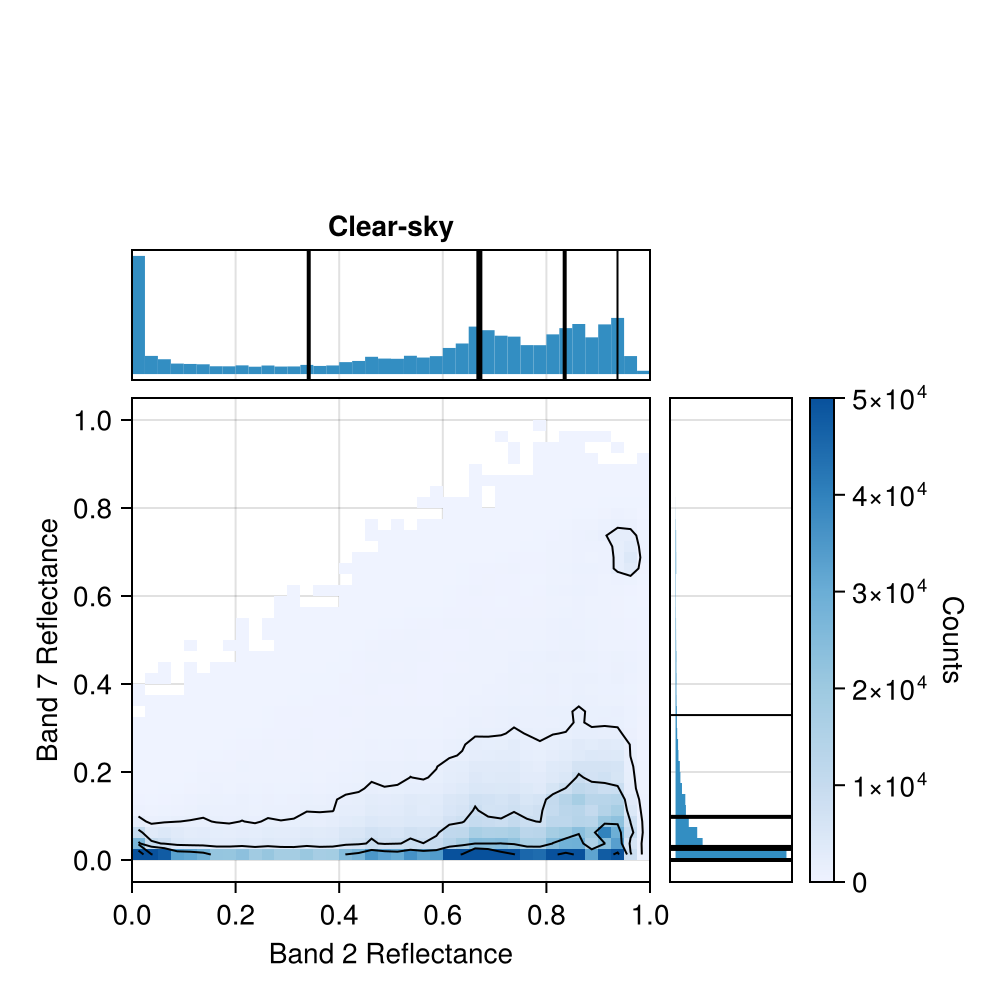

In [22]:
fig2 = Figure(size=(500,500))

#### Non-cloudy pixels
bins = 0:0.025:1

h2 = Hist1D(b2_non_clouds; binedges=bins);
h7 = Hist1D(b7_non_clouds, binedges=bins);
h2h7 = Hist2D((b2_non_clouds, b7_non_clouds), binedges=(bins, bins));

H = h2h7.bincounts
s = integral(h2h7)
Hd = H ./ s
F = range(0, maximum(Hd), 50)
L = round.([1-sum(Hd[Hd .> f]) for f in F], digits=3)

df = DataFrame(F=F, L=L)
df = df[.!nonunique(df, "L"), :];

pct = [0.05, 0.25, 0.5, 0.75, 0.95]
f = linear_interpolation(df[:, :L], df[:, :F])
levels = f.(pct) * s;

ax1, _ = hist(fig2[1, 1],h2; axis=(xticks=0:0.2:1, yticks=[], title="Clear-sky"))
ax3, _h2h7 = plot(fig2[2, 1], h2h7; colormap=:Blues_6, colorrange=(0, 5e4),
    axis=(ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance", xticks=0:0.2:1, yticks=0:0.2:1))
contour!(ax3, h2h7; 
    levels=levels, labels=false, color=:black)
Colorbar(fig2[2, 3], _h2h7; label="Counts", labelrotation=-pi/2)
ax2, _ = hist(fig2[2, 2], h7; direction=:x, axis=(yticks=0:0.2:1, xticks=[]))
ax2.aspect = 0.25
ax1.aspect = 4
b2_qs = quantile(b2_non_clouds, [0.05, 0.25, 0.5, 0.75, 0.95])
println("B2 quantiles", b2_qs)
vlines!(ax1, b2_qs, color=:black, linewidth=1)
vlines!(ax1, b2_qs[[2, 4]], color=:black, linewidth=2)
vlines!(ax1, b2_qs[[3]], color=:black, linewidth=3)


b7_qs = quantile(b7_non_clouds, [0.05, 0.25, 0.5, 0.75, 0.95])
println("B7 quantiles", b7_qs)
hlines!(ax2, b7_qs, color=:black, linewidth=1)
hlines!(ax2, b7_qs[[2, 4]], color=:black, linewidth=2)
hlines!(ax2, b7_qs[[3]], color=:black, linewidth=3)


linkyaxes!(ax3, ax2)
linkxaxes!(ax3, ax1)
hidedecorations!(ax1, grid = false)
hidedecorations!(ax2, grid = false)
colgap!(fig2.layout, -90)
rowgap!(fig2.layout,  -80)
# statbox!(fig, h2h7; position=(2,4))
save("../figures/fig_04b_non_cloud_histogram.pdf", fig2)
save("../figures/fig_04b_non_cloud_histogram.png", fig2, px_per_unit=1)

fig2

B1 quantiles[0.0, 0.43137254901960786, 0.7294117647058823, 0.8627450980392157, 0.9450980392156862]


# Calibrate t2 and t7 for cloud mask
We compute the f1 score as a function of the true positive, false positive, and false negative rate, relative to the MODIS cloud mask.

In [23]:
results_b7_b201 = []
for b7_thresh in range(0, 1, 11)
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.1, tau_b7=b7_thresh)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b7_b201, mean(df[.!isnan.(df.f1), :f1]))
end

results_b7_b203 = []
for b7_thresh in range(0, 1, 11)
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.3, tau_b7=b7_thresh)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b7_b203, mean(df[.!isnan.(df.f1), :f1]))
end

results_b7_b205 = []
for b7_thresh in range(0, 1, 11)
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.5, tau_b7=b7_thresh)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b7_b205, mean(df[.!isnan.(df.f1), :f1]))
end

In [24]:
results_b2_b701 = []
for b2_thresh in range(0, 1, 11)
    # true positive rate needs to have tp + fn in denom
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=b2_thresh, tau_b7=0.1)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b2_b701, mean(df[.!isnan.(df.f1), :f1]))
end

results_b2_b703 = []
for b2_thresh in range(0, 1, 11)
    # true positive rate needs to have tp + fn in denom
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=b2_thresh, tau_b7=0.3)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b2_b703, mean(df[.!isnan.(df.f1), :f1]))
end

results_b2_b705 = []
for b2_thresh in range(0, 1, 11)
    # true positive rate needs to have tp + fn in denom
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=b2_thresh, tau_b7=0.5)
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_b2_b705, mean(df[.!isnan.(df.f1), :f1]))
end

In [51]:
# TODO: Loop through training cases with floe data, get segment data
sea_ice_floe_cases = subset(coalesce.(train_cases.info, 0), :maximum_floe_size => r -> r .> 64);
df_list = []
for df_row in eachrow(sea_ice_floe_cases)
    idx = df_row.lookup_index
    img = SegmentedImage(fc_imgs[idx], label_components(sea_ice_floes[idx]))
    mean_colors = segment_mean(img)
    df = regionprops_table(img; properties=[:label, :bbox, :centroid, :area])
    df[:, :b7_mean] = [red(mean_colors[l]) for l in df[:, :label]]
    df[:, :b2_mean] = [green(mean_colors[l]) for l in df[:, :label]]
    df[:, :b1_mean] = [blue(mean_colors[l]) for l in df[:, :label]]
    df[:, :case_number] .= df_row.case_number

    # cloud fraction (MODIS)
    img = SegmentedImage(modis_cloud_masks[idx], label_components(sea_ice_floes[idx]))
    mean_fracs = segment_mean(img)
    df[:, :cloud_fraction] = [mean_fracs[l] for l in df[:, :label]]
    push!(df_list, df)
end

df_all = vcat(df_list..., cols=:union)

nothing

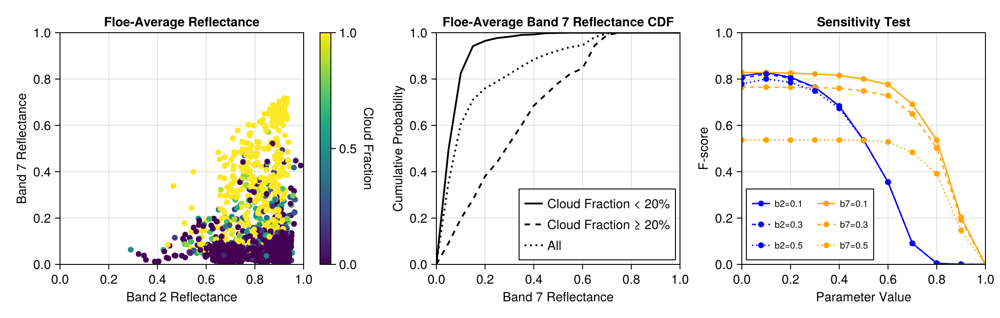

In [38]:
# Calibration plot, pt. 2
# Left: Scatter plot of ice floes, potentially add water patches
# Center: Cumulative distribution function for ice floes
# Right: f_1 scores against calibration data

f = Figure(size=(1100, 350))
ax1 = CairoMakie.Axis(f[1, 1], title="Floe-Average Reflectance",
    ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))

a = scatter!(ax1, df_all[:, :b2_mean], df_all[:, :b7_mean], color=df_all[:, :cloud_fraction], colormap=:viridis)
Colorbar(f[1, 2], a; label="Cloud Fraction", labelrotation=-pi/2)

ax2 = CairoMakie.Axis(f[1, 3], title="Floe-Average Band 7 Reflectance CDF",
    ylabel="Cumulative Probability", xlabel="Band 7 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))


frac_less = x -> mean(df_all[df_all.cloud_fraction .< 0.2, :b7_mean] .< x)
lines!(ax2, 0:0.05:1, frac_less.(0:0.05:1), color=:black, linestyle=:solid, linewidth=2, label="Cloud Fraction < 20%")

frac_less = x -> mean(df_all[df_all.cloud_fraction .>= 0.2, :b7_mean] .< x)
lines!(ax2, 0:0.05:1, frac_less.(0:0.05:1), color=:black, linestyle=:dash, linewidth=2, label="Cloud Fraction ≥ 20%")

frac_less = x -> mean(df_all[:, :b7_mean] .< x)
lines!(ax2, 0:0.05:1, frac_less.(0:0.05:1), color=:black, linestyle=:dot, linewidth=2, label="All")
Legend(f[1, 3], ax2; tellheight=false, tellwidth=false, halign=:right, valign=:bottom, margin=(5, 5, 5, 5))

ax3 = CairoMakie.Axis(f[1, 4], title="Sensitivity Test",
    ylabel="F-score", xlabel="Parameter Value", yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1)
)

scatterlines!(ax3, range(0, 1, 11), results_b7_b201, marker=:circle, color=:blue, label="b2=0.1")
scatterlines!(ax3, range(0, 1, 11), results_b2_b701, marker=:circle, color=:orange, label="b7=0.1")
scatterlines!(ax3, range(0, 1, 11), results_b7_b203, marker=:circle, color=:blue, linestyle=:dash, label="b2=0.3")
scatterlines!(ax3, range(0, 1, 11), results_b2_b703, marker=:circle, color=:orange, linestyle=:dash, label="b7=0.3")
scatterlines!(ax3, range(0, 1, 11), results_b7_b205, marker=:circle, color=:blue, linestyle=:dot, label="b2=0.5")
scatterlines!(ax3, range(0, 1, 11), results_b2_b705, marker=:circle, color=:orange, linestyle=:dot, label="b7=0.5")
Legend(f[1, 4], ax3;
    tellheight = false,
    tellwidth = false, 
    halign=:left, 
    valign=:bottom, 
    margin=(5, 5, 5, 5), 
    labelsize=10,
    nbanks=2)
save("../figures/fig_04_cde.png", f)
current_figure()

B1 quantiles[0.0, 0.027450980392156862, 0.43137254901960786, 0.7294117647058823, 0.8627450980392157, 0.9294117647058824, 0.9450980392156862]


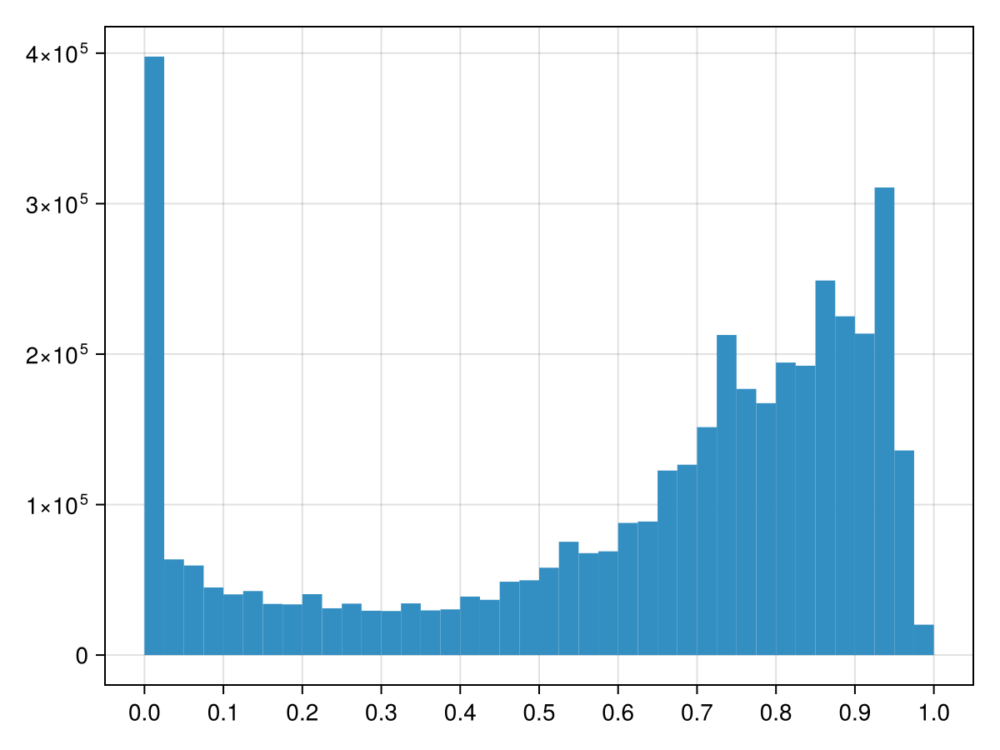

In [29]:
# Calibrating the sea ice mask
b1_qs = quantile(b1_non_clouds, [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
println("B1 quantiles", b1_qs)

h1 = Hist1D(b1_non_clouds; binedges=bins)

f = Figure()
ax, _ = hist(f[1, 1], h1; direction=:y, axis=(yticks=0:1e5:1e6, xticks=0:0.1:1))
current_figure()

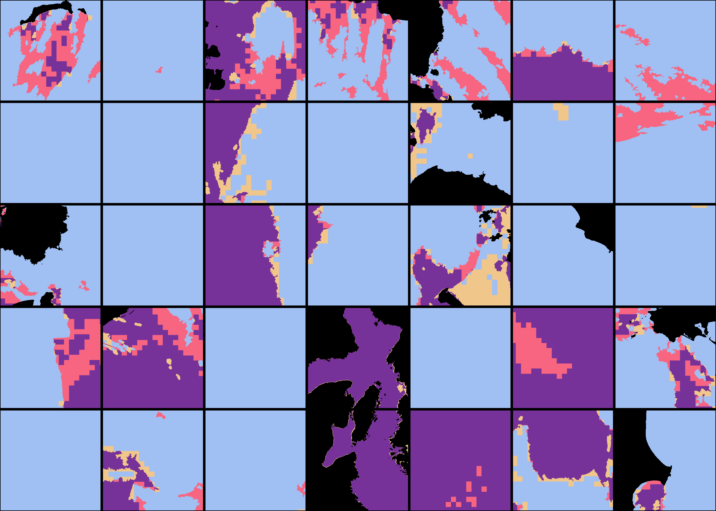

In [30]:
idx = train_cases.info.lookup_index[46:2:115]
ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.25, tau_b7=0.16)
apply_landmask!.(ift_cloudmask, land_masks .|> r -> r .> 0)
mosaicview(visualize_cloud_confusion_matrix.(
        ift_cloudmask[idx],
        modis_cloud_masks[idx],
        land_masks[idx]), nrow=5, npad=10, fillvalue=RGBA(0,0,0,0))

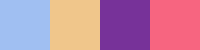

In [15]:
tpcolor, fpcolor, tncolor, fncolor = RGB(160/255, 191/255, 242/255), RGB(240/255, 198/255, 139/255), RGB(119/255, 50/255, 153/255), RGB(247/255, 101/255, 128/255)
mosaicview([ones((5,5)) .* c for c in [tpcolor, fpcolor, tncolor, fncolor]], nrow=1)

In the above: solid lines are using 0.1, dashed 0.3, and dotted 0.5.

Finding: The cloud mask is mainly sensitive to the Band 7 parameter, which is expected, and regardless of band 7 parameter, we don't see much drop off in f1 score as the band 2 parameter varies until it reaches 0.5, with only minor changes up to 0.6. For band 7, we find only small changes with the choice of Band 2 parameter, and find that the f1 score drops off with varying band 7 parameter fairly quickly between 0.2 and 0.3. 

Next stage: We need to understand a few more things. 
* How sensitive is the result to the choice of cleanup parameters?
* Where do validated ice floes fall in the diagram? How much does the cloud cover vary?
* If we use the algorithm as-is, how many floes are obscured, and are we okay with it?
  



In [401]:
results_se_opening = []
for se_opening_diameter in 1:10
    # true positive rate needs to have tp + fn in denom
    ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.4, tau_b7=0.2, opening_strel=strel_disk(se_opening_diameter))
    test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
    df = reduce(vcat, test);
    df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
    df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
    df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
    push!(results_se_opening, mean(df[.!isnan.(df.f1), :f1]))
end

# results_b2_b703 = []
# for b2_thresh in range(0, 1, 11)
#     # true positive rate needs to have tp + fn in denom
#     ift_cloudmask = CloudMask.(fc_imgs; tau_b2=b2_thresh, tau_b7=0.3)
#     test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
#     df = reduce(vcat, test);
#     df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
#     df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
#     df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
#     push!(results_b2_b703, mean(df[.!isnan.(df.f1), :f1]))
# end

# results_b2_b705 = []
# for b2_thresh in range(0, 1, 11)
#     # true positive rate needs to have tp + fn in denom
#     ift_cloudmask = CloudMask.(fc_imgs; tau_b2=b2_thresh, tau_b7=0.5)
#     test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
#     df = reduce(vcat, test);
#     df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
#     df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
#     df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
#     push!(results_b2_b705, mean(df[.!isnan.(df.f1), :f1]))
# end

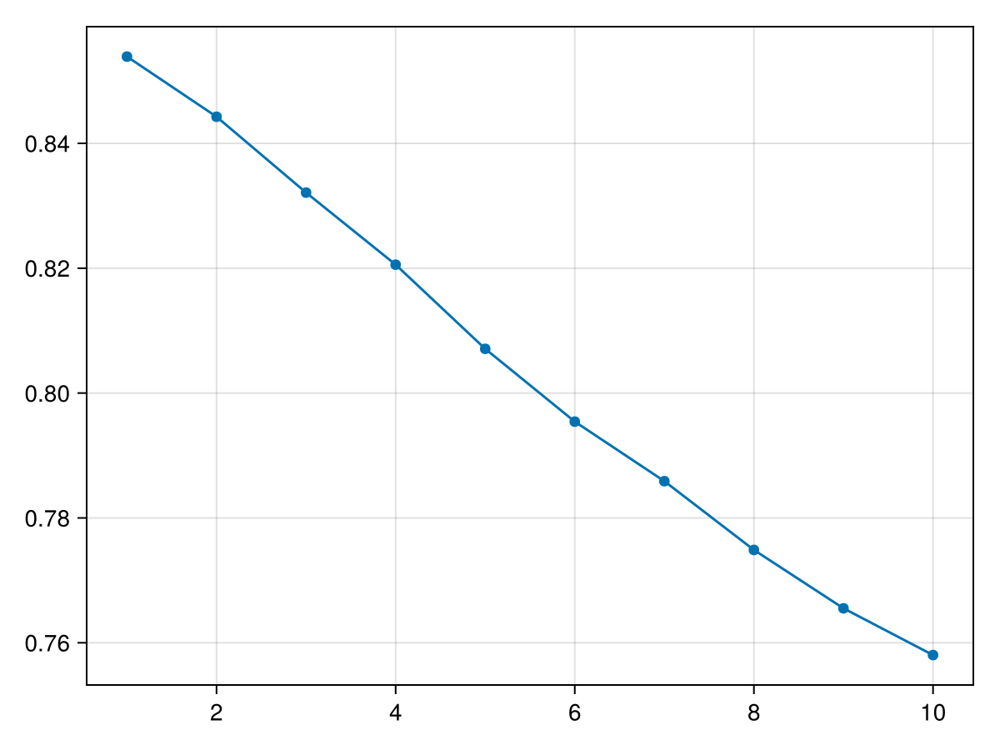

In [406]:
scatterlines(results_se_opening, marker=:circle)

# Compute f1 score

In [135]:
ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.34, tau_b7=0.16, opening_strel=strel_disk(1))
test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
df = reduce(vcat, test);
df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
mean(df[.!isnan.(df.f1), :f1])

0.8221960832846604

## Visualize floe-wise measures
The goal of the calibration for the ice/water/cloud masks is to have as high correspondence as possible with the MODIS mask, while allowing some ice floes under thin clouds to be detected. 

In [65]:
frac_less = x -> mean(df_all[df_all.cloud_fraction .< 0.2, :b7_mean] .< x)
x = 0.1:0.01:0.4

pct = [0.9, 0.95, 0.99]
f = linear_interpolation(frac_less.(x), x)
levels = f.(pct)

┌ Warning: Duplicated knots were deduplicated. Use Interpolations.deduplicate_knots!(knots) explicitly to avoid this warning.
│   k1 =
│    31-element Vector{Float64}:
│     0.8247619047619048
│     0.8657142857142858
│     0.9028571428571428
│     0.92
│     0.9314285714285714
│     ⋮
│     0.9914285714285714
│     0.9923809523809524
│     0.9923809523809524
│     0.9923809523809524
│     0.9923809523809524
└ @ Interpolations ~/.julia/packages/Interpolations/dR5oF/src/gridded/gridded.jl:81


3-element Vector{Float64}:
 0.11923076923076924
 0.1594444444444444
 0.3449999999999994

Interpolation of the survival function for the sea ice floes Band 7 reflectance: with b7 at 0.12, we have 90% of ice floes, at 0.16, we have 95%, and at 0.34, we have 99%. 

In [54]:
frac_greater = x -> mean(df_all[df_all.cloud_fraction .> 0.2, :b7_mean] .< x)
x = 0.:0.01:0.4
f = linear_interpolation(x, frac_greater.(x))
f.(levels)

3-element Vector{Float64}:
 0.22886317222600408
 0.29636184857423786
 0.5929203539822999

From these numbers, the cloudy ice floes have 23% visible, 30%, or 59%. So setting t7 to 0.35 results in retaining 99% of clear-sky floes and 59% of cloudy floes.


# Ice-water discrimination
The basic method will work most of the time, but has some issues in places where there are thin clouds over water. This could be resolved in the cloud mask, but the idea for the next part is to have a full pixel-wise split. If it's not ice, it's water, in this method. 

TBD: We need to test what the minimum number of pixels required 



In [136]:
ift_cloudmask = CloudMask.(fc_imgs; tau_b7=0.15, tau_b2=0.34, opening_strel=strel_disk(3));
masked_tc = apply_landmask.(apply_landmask.(tc_imgs, ift_cloudmask), land_masks);

## Sensitivity of the ice-water mask to the minimum brightness

In [137]:
# Compute the cloud fraction and ice fraction, since if cloud fraction = 1 ice fraction is undefined.
cloud_fraction = (cm, lm) -> round(mean(cm[.!lm]), digits=2)
ice_fraction = (cm, im, lm) -> round(mean(im[.! (lm .|| cm)]), digits=2)
cloudfrac = cloud_fraction.(ift_cloudmask, land_masks)

results = []
for band_1_min in 0.1:0.05:0.5
    ift_icemask = IceDetectionBrightnessPeaksMODIS134(band_1_min=band_1_min).(masked_tc)
    icefrac = ice_fraction.(ift_cloudmask, ift_icemask, land_masks);
    push!(results, icefrac)
end

# Add columns to dataframe
df = DataFrame(cloudfrac=cloudfrac)
vals = collect(0.1:0.05:0.5)
for (val, res) in zip(vals, results)
    df[:, "b1_min_"*string(val)]= res
end
df = df[df.cloudfrac .< 1.0, :];

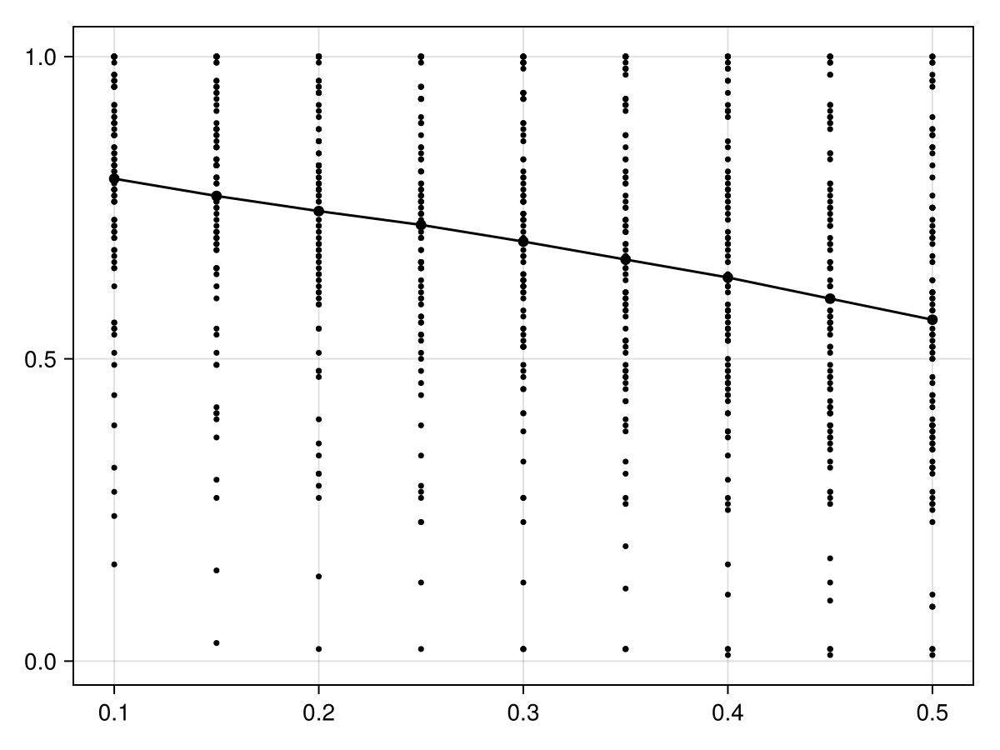

In [138]:
scatter(vals, collect(df[1, Not(:cloudfrac)]),  color=:black, markersize=5)
for data in eachrow(df[:, Not(:cloudfrac)])
    scatter!(vals, collect(data), color=:black, markersize=5)
end
scatterlines!(vals, mean.(eachcol(df[:, Not(:cloudfrac)])), color=:black)
current_figure()

In [139]:
# Average slope for each step of 0.05
ave = mean.(eachcol(df[:, Not(:cloudfrac)]))
mean(diff(ave))

-0.029157303370786536

Misclassification: How many ice floe pixels get classified as sea ice under different thresholds?
Compute number of ice pixels, number as ice, number as water, number as cloud.

In [140]:
binary_floes = sea_ice_floes .|> r -> r .> 0;

In [142]:
# Compute the cloud fraction and ice fraction, since if cloud fraction = 1 ice fraction is undefined.
ice_total = []
floe_total = []
floe_as_ice = []
floe_as_water = []

sum_mask = mask -> sum(mask)
comp_floe_cloud = (floe_mask, cloud_mask) -> sum(floe_mask .&& cloud_mask)
comp_floe_water = (floe_mask, cloud_mask, ice_mask) -> sum(floe_mask .&& .!(cloud_mask .|| ice_mask))
comp_floe_ice = (floe_mask, ice_mask) -> sum(floe_mask .&& ice_mask)

floe_total = sum_mask.(binary_floes)
cloud_total = sum_mask.(ift_cloudmask)
floe_as_cloud = comp_floe_cloud.(binary_floes, ift_cloudmask)
clearsky_floe_total = floe_total .- floe_as_cloud
vals = collect(0.05:0.05:0.8)
for band_1_min in vals
    ift_icemask = IceDetectionBrightnessPeaksMODIS134(band_1_min=band_1_min).(masked_tc)
    push!(ice_total, sum_mask.(ift_icemask))
    push!(floe_as_ice, comp_floe_cloud.(binary_floes, ift_icemask))
    push!(floe_as_water, comp_floe_water.(binary_floes, ift_cloudmask, ift_icemask))
end

# Add columns to dataframe
n_ocean = 400*400 .- sum_mask.(land_masks)
n_clearsky_ocean = n_ocean .- sum_mask.(ift_cloudmask)
df_floe_measures = DataFrame(n_ocean=n_ocean,
    n_clearsky_ocean=n_clearsky_ocean,
    floe_total=floe_total, 
    cloud_total=cloud_total, 
    floe_as_cloud=floe_as_cloud,
    n_clearsky_floes=clearsky_floe_total)
for (val, res) in zip(vals, ice_total)
    df_floe_measures[:, "total_ice_b1_min_"*string(val)] = res
end
for (val, res) in zip(vals, floe_as_water)
    df_floe_measures[:, "floe_as_water_b1_min_"*string(val)] = res
end
for (val, res) in zip(vals, floe_as_ice)
    df_floe_measures[:, "floe_as_ice_b1_min_"*string(val)] = res
end
nothing

In [125]:
sum(df_floe_measures[:, :floe_as_cloud]) / sum(df_floe_measures[:, :floe_total])

0.3769774862217462

In [143]:
cols = ["total_ice_b1_min_"*string(val) for val in vals]
total_ice = sum.(eachcol(df_floe_measures[:, cols])) ./ sum(df_floe_measures[:, :n_clearsky_ocean])
cols = ["floe_as_ice_b1_min_"*string(val) for val in vals]
floes_as_ice = sum.(eachcol(df_floe_measures[:, cols])) ./ sum(df_floe_measures[:, :n_clearsky_floes])
cols = ["floe_as_water_b1_min_"*string(val) for val in vals]
floes_as_water = sum.(eachcol(df_floe_measures[:, cols])) ./ sum(df_floe_measures[:, :n_clearsky_floes])

16-element Vector{Float64}:
 0.0028078217892701096
 0.00346918797602846
 0.004144879784160638
 0.005121409641143185
 0.006114652723061863
 0.0075639280853807035
 0.009435809278227443
 0.011715970680228255
 0.015306926437934245
 0.021435904782369935
 0.03259556383258124
 0.05398849175082969
 0.08180168564811499
 0.13470859298522073
 0.2449394742496956
 0.3446720626507175

In [146]:
floes_as_ice[vals .== 0.45]

1-element Vector{Float64}:
 0.9846930735620657

In [148]:
floes_as_water[vals .== 0.45], floes_as_water[vals .== 0.8]

([0.015306926437934245], [0.3446720626507175])

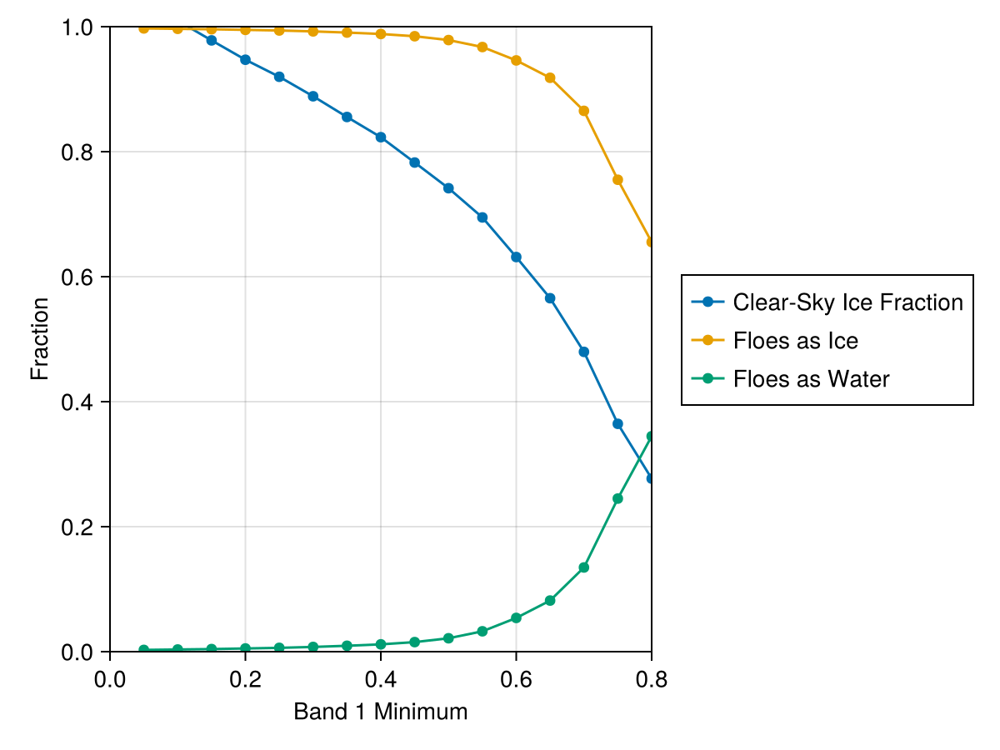

In [144]:
f = Figure()
a, _ = scatterlines(f[1,1], vals, total_ice, 
    axis=(ylabel="Fraction", xlabel="Band 1 Minimum",
        yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 0.8, 0, 1)),
    label="Clear-Sky Ice Fraction")
scatterlines!(f[1,1], vals, floes_as_ice, label="Floes as Ice")
scatterlines!(f[1,1], vals, floes_as_water, label="Floes as Water")
Legend(f[1,2], a)
current_figure()

## Ice-Mask Calibration discussion

Using the labeled floes as the reference point, I computed (a) the clear-sky ice fraction, (b) the fraction of ice floes classified as sea ice, and (c) the fraction of ice floe pixels classified as water.

The clear-sky ice fraction decreases linearly (as described previously) until approximately 0.5, then drops more steeply.

The maximum of the floes-as-ice category depends on the number of cloud-covered floes. 62% of ice floes are classified as clear-sky with the IFT cloud mask.

The misclassification rate of sea ice floes as water stays steady and low up until 0.4, then starts to rise. It rises gradually until about 0.65, then rises steeply. Note though that even at t1 = 0.8, we still have more floes being classified as ice than we do as water. 

TBD: Fraction of water samples classified as ice

# Visualization

In [39]:
function visualize_results(cloud_mask, land_mask, ice_mask;
        land_color=land_color, ocean_color=ocean_color, cloud_color=cloud_color,
        floe_color=floe_color)
    img = RGB.(ocean_color .* ones(size(cloud_mask))) 
    img[land_mask .> 0] .= land_color
    img[(cloud_mask .> 0) .&& (land_mask .== 0)] .= cloud_color
    img[(ice_mask .> 0)] .= floe_color
    return RGBA.(img)
end

visualize_results (generic function with 1 method)

## Note for future version
If there are two major peaks, then we tend to pick the lower peak. In this image, that results in error. Having a high value for the threshold works better in this case.

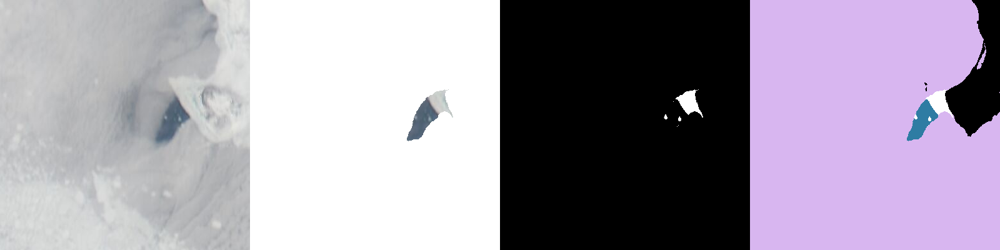

In [48]:
index = 49
# 1> Cloud mask and land mask applied
# 2> Initial output of ice mask (thresholds)
# 3> Filter to only include low Band 7
masked_tc = apply_landmask.(tc_imgs, land_masks)
masked_tc .= apply_landmask.(masked_tc, ift_cloudmask)
masked_fc = apply_landmask.(fc_imgs, land_masks)
masked_fc .= apply_landmask.(masked_fc, ift_cloudmask)

ift_icemasks = IceDetectionBrightnessPeaksMODIS134(band_1_min=0.5).(masked_tc);
mosaicview(tc_imgs[index], masked_tc[index],
    Gray.(ift_icemasks[index]), visualize_results(ift_cloudmask[index], land_masks[index], ift_icemasks[index]), nrow=1)

This example shows a case where there are two modes in the histogram. Ideally we split these two modes. If we use too low a threshold, we end up calling water ice. Most of the region above is clearly blue, but it is a brighter blue. 

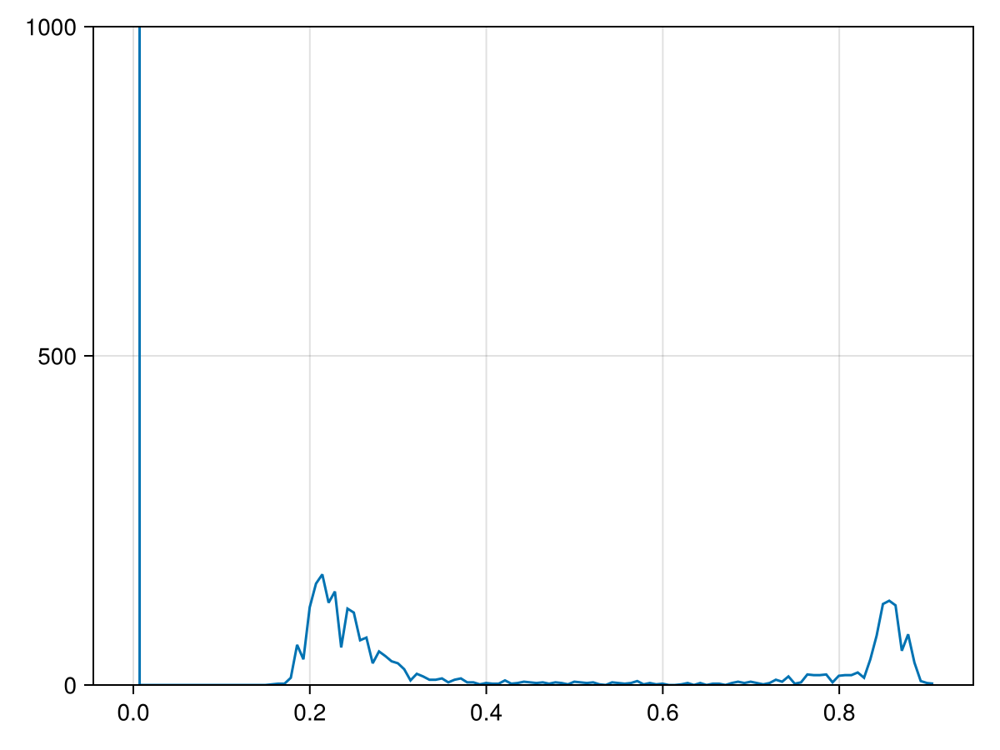

In [49]:
# Red-band histogram
edges, counts = build_histogram(blue.(masked_fc[index]), 128)
lines(edges, counts[1:end])
ylims!(0, 1e3)
current_figure()

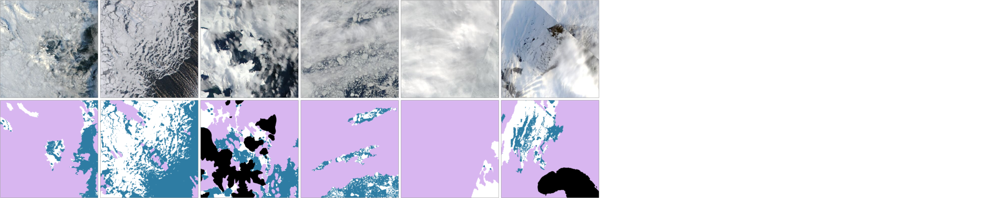

In [65]:
idx = sea_ice_floe_cases[:, :lookup_index][15:20]
mosaicview(
    mosaicview(tc_imgs[idx], ncol=10, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    mosaicview(
        visualize_results.(ift_cloudmask[idx], land_masks[idx] .|>  r -> r .> 0, ift_icemasks[idx]),
        ncol=10, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    
    npad=10, fillvalue=RGBA(0,0,0,0),
    nrow=2)

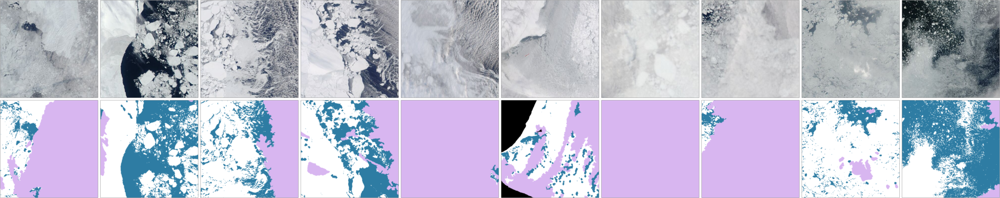

In [73]:
idx = sea_ice_floe_cases[:, :lookup_index][40:end]
mosaicview(
    mosaicview(tc_imgs[idx[10:19]], ncol=10, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    mosaicview(
        visualize_results.(ift_cloudmask[idx[10:19]], land_masks[idx[10:19]] .|>  r -> r .> 0, ift_icemasks[idx[10:19]]),
        ncol=10, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    
    npad=10, fillvalue=RGBA(0,0,0,0),
    nrow=2)

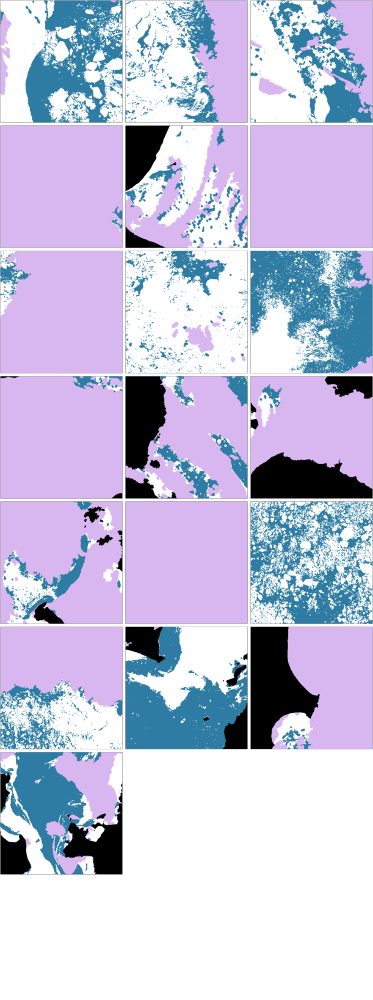

In [69]:
img_classified = mosaicview(visualize_results.(
        ift_cloudmask[idx], 
        land_masks[idx],
        ift_icemasks[idx]),
    nrow=8, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
save("../figures/classification_results.png", img_classified)
img_classified

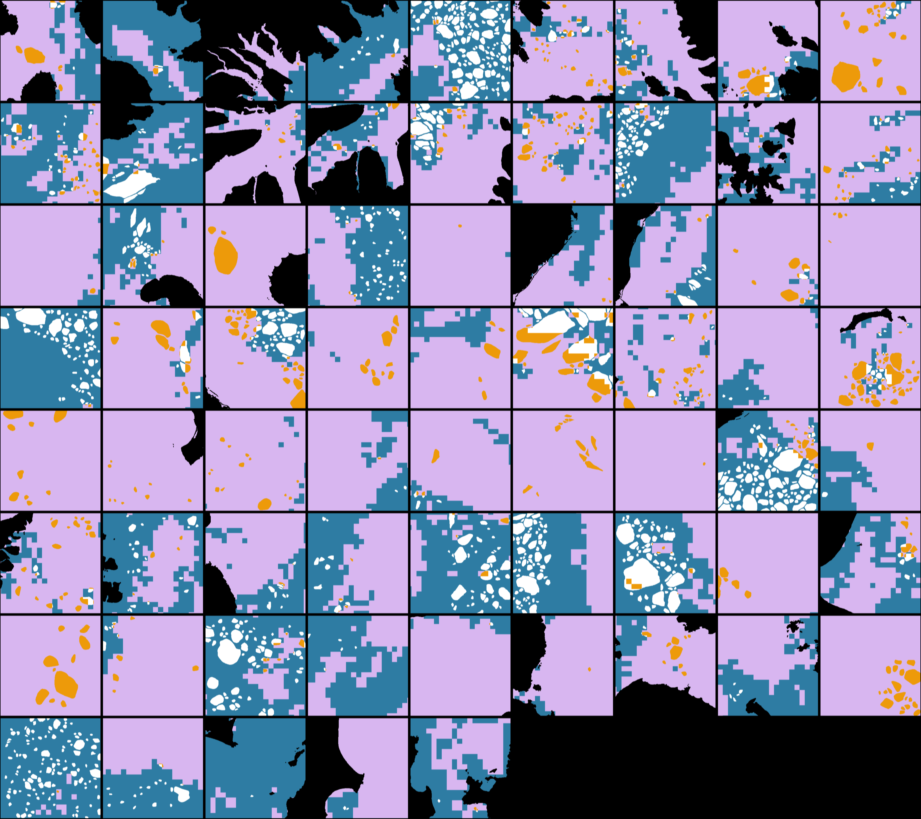

In [108]:
img_comparison_modis = mosaicview(visualize_ice_under_cloud.(sea_ice_floes[idx],
        modis_cloud_masks[idx], land_masks[idx]), nrow=8, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
save("../figures/modis_cloud_floe_labels.png", img_comparison_modis)
img_comparison_modis

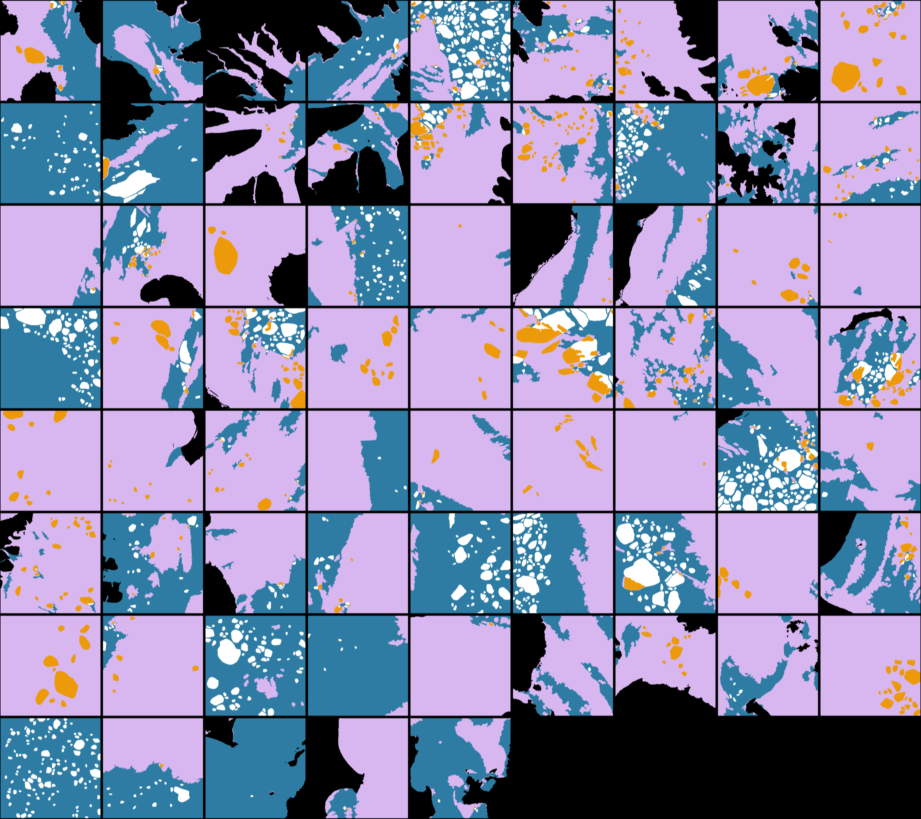

In [60]:
img_comparison_julia = mosaicview(visualize_ice_under_cloud.(sea_ice_floes[idx],
        ift_cloudmask[idx], land_masks[idx]), nrow=8, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
save("../figures/julia_cloud_floe_labels.png", img_comparison_julia)
img_comparison_julia

# Validation
We now turn to the test cases. There's not as many, so let's look at all of them.

Here, I want to use the metadata and whatever labeled data is available to compute error metrics. 

In [17]:
tc_imgs = modis_truecolor.(test_cases)
fc_imgs = modis_falsecolor.(test_cases)
sea_ice_floes = validated_binary_floes.(test_cases)
land_masks = modis_landmask.(test_cases) .|> r -> r .> 0; # Load land masks and convert to binary
landfast_ice_masks = validated_binary_landfast.(test_cases);

# Add column with cloud fraction path
cloudfrac_loc = "../data/cloudfraction_numeric/"
transform!(test_cases.info, [:case_number, :region, :satellite, :start_date] => ByRow((cn, r, s, d) ->
    join([lpad(cn, 3, "0"), r, Dates.format(d, "yyyymmdd"), s, "cloudfraction.csv"], "-")) => :cloudfrac_file)

# Load numeric cloud fraction data
modis_cloudfrac = load.(joinpath.(cloudfrac_loc, test_cases.info[:, :cloudfrac_file])) .|> 
                            DataFrame .|> r -> Array(r[:, 2:end]);

fill_missing!(landfast_ice_masks)
fill_missing!(sea_ice_floes)

# compute MODIS estimated cloud fraction for all pixels
test_cases.info[:, :lookup_index] .= 1:length(test_cases) # This gives us the index for the data loaders
test_cases.info[:, "cloud_fraction_modis"] = round.(mean.(modis_cloudfrac) ./ 100, digits=2);
test_cases.info[:, "cloud_fraction_modis_ocean"] = round.(masked_mean.(modis_cloudfrac, land_masks)./ 100, digits=2);

LoadError: UndefVarError: `fill_missing!` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [18]:
test_cases.info[:, :lookup_index] .= 1:length(test_cases) # This gives us the index for the data loaders
test_cases.info[:, "cloud_fraction_modis"] = round.(mean.(modis_cloudfrac) ./ 100, digits=2);
test_cases.info[:, "cloud_fraction_modis_ocean"] = round.(masked_mean.(modis_cloudfrac, land_masks)./ 100, digits=2);

LoadError: UndefVarError: `masked_mean` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [19]:
modis_cloud_masks = [m .> 75 for (m, f) in zip(modis_cloudfrac, fc_imgs)] 
ift_cloudmask = CloudMask.(fc_imgs; tau_b7=0.16, tau_b2=0.34, opening_strel=strel_disk(3));
masked_tc = apply_landmask.(apply_landmask.(tc_imgs, ift_cloudmask), land_masks);
ift_icemasks = IceDetectionBrightnessPeaksMODIS134(band_1_min=0.45).(masked_tc);

In [20]:
length(test_cases.info[:, :case_number])

74

In [21]:
length(train_cases.info[:, :case_number])

115

In [22]:
# Cases:
# Fully cloud covered: 20 cases, with an additional 24 with 80 or 90 % cloud cover.

In [23]:
idx = test_cases.info[test_cases.info.visible_sea_ice .== "no", :lookup_index]

17-element Vector{Int64}:
 10
 13
 14
 22
 26
 28
 32
 36
 38
 42
 48
 50
 57
 64
 70
 71
 74

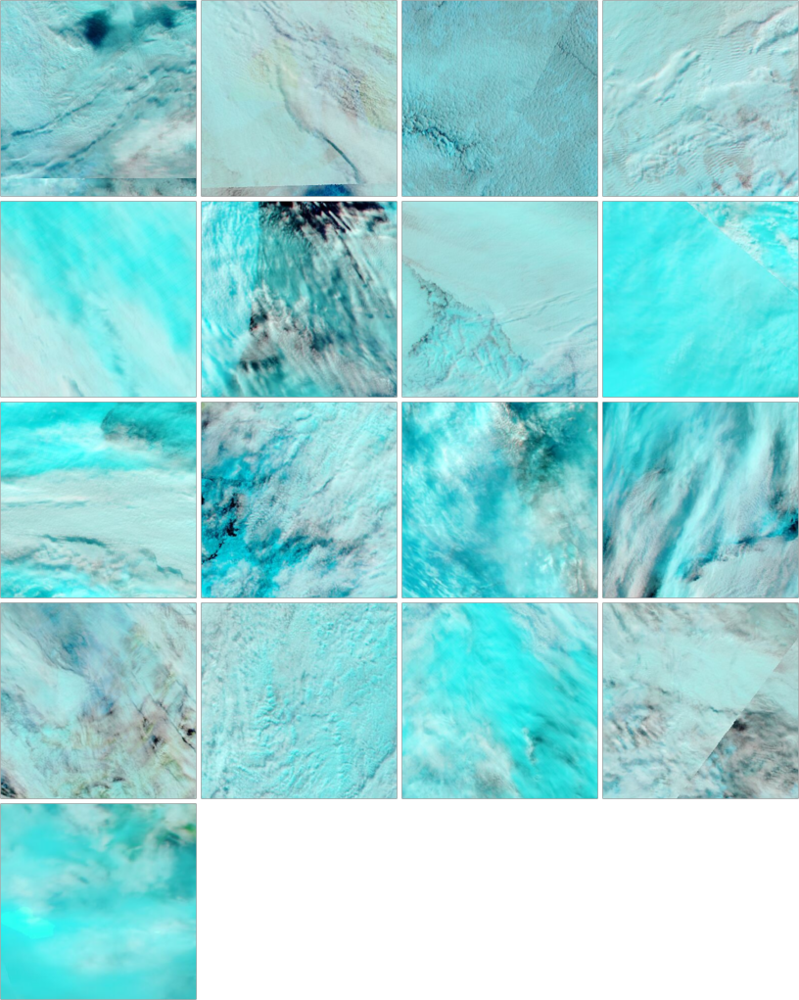

In [24]:
# idx = test_cases.info[test_cases.info.cloud_fraction_manual .>= 0.9, :lookup_index];
mosaicview(fc_imgs[idx],   nrow=5, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)

# Cases where visible sea ice = "no"
Out of the non-water pixels, the options are land, ice, or cloud. So we could compute 

In [25]:
img_classified = mosaicview(visualize_results.(
        ift_cloudmask[idx], 
        land_masks[idx],
        ift_icemasks[idx]),
    nrow=5, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)

LoadError: UndefVarError: `visualize_results` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

## Overall comparison: MODIS, manual, IFT

In [26]:
ift_cloudfrac = masked_mean.(ift_cloudmask, land_masks)
modis_cloudfract_vec = masked_mean.(modis_cloud_masks, land_masks)
manual_frac = test_cases.info[:, :cloud_fraction_manual];

LoadError: UndefVarError: `masked_mean` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [27]:
# scatter(manual_frac, modis_cloudfract_vec, label="MODIS Cloud Mask", color=:black)
# scatter!(manual_frac, ift_cloudfrac, label="IFT Cloud Mask", color=:red)
fig = Figure()
ax = CairoMakie.Axis(fig[1, 1], xticks=0:0.1:1, yticks=0:0.1:1, xlabel="MODIS Cloud Fraction", ylabel="IFT Cloud Fraction")

scatter!(ax, modis_cloudfract_vec, ift_cloudfrac, color=:blue)
lines!(ax, [0, 1], [0, 1], color=:black, linestyle=:dash)
current_figure()

LoadError: UndefVarError: `modis_cloudfract_vec` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [28]:
StatsBase.cor(ift_cloudfrac, modis_cloudfract_vec)

LoadError: UndefVarError: `ift_cloudfrac` not defined in `Main`
Suggestion: add an appropriate import or assignment. This global was declared but not assigned.

In [29]:
test_cases.info[abs.(modis_cloudfract_vec .- ift_cloudfrac) .> 0.5, :]

LoadError: UndefVarError: `modis_cloudfract_vec` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [30]:
ift_cloudmask = CloudMask.(fc_imgs; tau_b2=0.34, tau_b7=0.16, opening_strel=strel_disk(1))
test = confusion_matrix.(modis_cloud_masks, ift_cloudmask, land_masks .|> r -> r .> 0);
df = reduce(vcat, test);
df[:, :tpr] = df[:, :tp] ./ (df[:, :tp] .+ df[:, :fn])
df[:, :fpr] = df[:, :fp] ./ (df[:, :tn] .+ df[:, :fp])
df[:, :f1] = 2 * df[:, :tp] ./ (2 * df[:, :tp] + df[:, :fp] + df[:, :fn])
mean(df[.!isnan.(df.f1), :f1])

0.849150513209947

In [31]:
idx = [14, 20, 27]
mosaicview(
    mosaicview(tc_imgs[idx],  nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    mosaicview([Gray.(m ./ 100) for m in modis_cloudfrac[idx]],  nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    mosaicview(visualize_results.(
        ift_cloudmask[idx], 
        land_masks[idx],
        ift_icemasks[idx]),
    nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true, nrow=1)

LoadError: UndefVarError: `visualize_results` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

## Cases with low cloud fraction

In [32]:
idx = test_cases.info[test_cases.info.cloud_fraction_manual .<= 0.1, :lookup_index];
mosaicview(
    mosaicview(tc_imgs[idx],  nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    mosaicview(visualize_results.(
        ift_cloudmask[idx], 
        land_masks[idx],
        ift_icemasks[idx]),
    nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true),
    npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true, nrow=1)

LoadError: UndefVarError: `visualize_results` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [33]:
mosaicview(visualize_results.(
        ift_cloudmask[idx], 
        land_masks[idx],
        ift_icemasks[idx]),
    nrow=5, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)

LoadError: UndefVarError: `visualize_results` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [34]:
function validated_binary_water(case::Case)
    info(case).water_sample == 0 && return nothing
    (; case_number, region, date, satellite) = IceFloeTracker.Data._filename_parts(case)
    file = "data/validation_dataset/binary_water_samples/$(case_number)-$(region)-$(date)-$(satellite)-binary_water_samples.png"
    img = file |> case.loader |> load |> binarize_mask .|> Gray
    return img
end

validated_binary_water (generic function with 1 method)

In [35]:
water_samples = validated_binary_water.(test_cases);

In [36]:
# Cases with validated water masks
water_idx = test_cases.info[test_cases.info.water_sample, :lookup_index]

12-element Vector{Int64}:
  1
  2
  3
  4
  5
 12
 16
 23
 52
 54
 62
 65

In [37]:
water_idx = [1, 2, 3, 12, 16, 23, 52, 54, 62, 65]

10-element Vector{Int64}:
  1
  2
  3
 12
 16
 23
 52
 54
 62
 65

In [38]:
overlays = []
for idx in water_idx
    
    cm_overlay = deepcopy(tc_imgs[idx])


    # Ice
    cm_overlay[ift_icemasks[idx]] .= floe_color
    
    # Water
    w_idx = .!ift_cloudmask[idx] .&& .!ift_icemasks[idx]
    cm_overlay[w_idx] .= ocean_color
        
     # Clouds
    cm_overlay[ift_cloudmask[idx] .> 0] .= cloud_color

    # Land
    cm_overlay[land_masks[idx]] .= land_color
    
    outlines = sea_ice_floes[idx] .- erode(sea_ice_floes[idx], strel_box((5,5)))
    cm_overlay[outlines .> 0] .= RGBA(1, 0, 0, 1)
    tc_copy = deepcopy(tc_imgs[idx])
    tc_copy[outlines .> 0] .= RGBA(1, 0, 0, 1)
    
    outlines = water_samples[idx] .- erode(water_samples[idx], strel_box((5,5)))
    tc_copy[outlines .> 0] .= RGBA(0.7, 0.8, 1, 1)
    cm_overlay[outlines .> 0] .= RGBA(0.7, 0.8, 1, 1)
    
    # Left: water samples, validated ice floes
    push!(overlays, mosaicview(tc_copy, cm_overlay, nrow=2, npad=10, fillvalue=RGBA(0,0,0,0)))
end

# mosaicview(overlays, nrow=1)
nothing

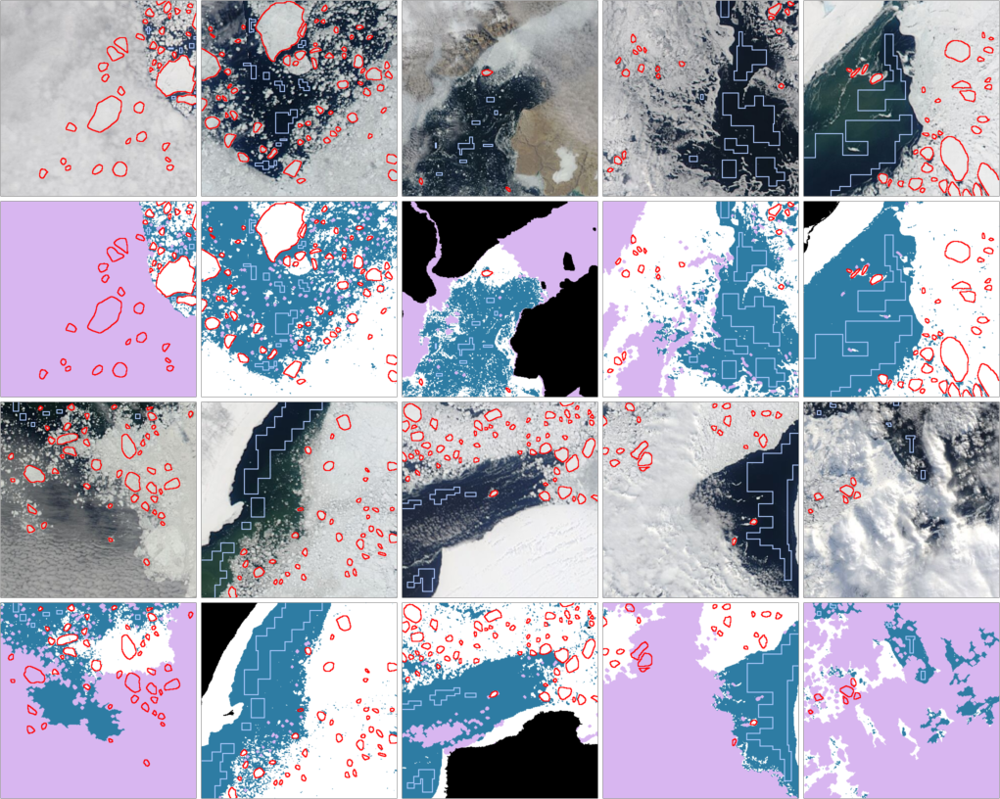

In [40]:
validation_img = mosaicview(overlays..., nrow=2, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
save("../figures/fig_06_validation_cloud_ice_mask.png", validation_img)
validation_img

In [373]:
test_cases.info[water_idx, [:case_number, :satellite, :region, :cloud_fraction_manual, :cloud_category_manual, :floe_obscuration]]

Row,case_number,satellite,region,cloud_fraction_manual,cloud_category_manual,floe_obscuration
,Int64,String,String,Float64,String,String
1,13,aqua,baffin_bay,0.8,thin,heavy
2,14,aqua,baffin_bay,0.1,none,none
3,15,terra,baffin_bay,0.4,scattered,heavy
4,32,aqua,barents_kara_seas,0.1,thin,none
5,48,aqua,beaufort_sea,0.0,none,none
6,67,aqua,bering_chukchi_seas,0.9,thin,light
7,128,aqua,hudson_bay,0.0,none,none
8,138,terra,hudson_bay,0.1,scattered,none
9,152,terra,laptev_sea,0.2,scattered,moderate


# Pixel counts
Validation of water samples. Table: N true, N labeled as water, N labeled as ice, N labeled as cloud

In [182]:
"""
Count number of pixels labeled in each category using the ice and cloud masks.
"""
function water_classification(
        binary_water, ice_mask, cloud_mask
    )
    idx = binary_water .> 0
    n_total = sum(idx)
    n_ice = sum(idx .&& ice_mask)
    n_water = sum(idx .&& .! ice_mask)
    n_cloud = sum(idx .&& cloud_mask)
    return [n_total, n_ice, n_water, n_cloud]
end
results = water_classification.(water_samples[water_idx], ift_icemasks[water_idx], ift_cloudmask[water_idx])

10-element Vector{Vector{Int64}}:
 [534, 0, 534, 0]
 [4239, 0, 4239, 0]
 [1431, 0, 1431, 0]
 [16401, 1, 16400, 0]
 [26738, 0, 26738, 0]
 [933, 0, 933, 0]
 [15429, 0, 15429, 0]
 [3773, 0, 3773, 0]
 [15292, 21, 15271, 0]
 [1001, 0, 1001, 2]

In [183]:
n_total, n_ice, n_water, n_cloud = sum(results)
println("TPR ", n_water/n_total)
println("FNR ", (n_ice + n_cloud) / n_total) # water labeled as ice + water labeled as cloud / total water labels

TPR 0.999743503048816
FNR 0.00027981485583705447


In [184]:
"""
Count number of pixels labeled in each category using the ice and cloud masks.

This doesn't account for mistakes in the cloud mask, though.
"""
function ice_floe_classification(
        binary_floes, ice_mask, cloud_mask
    )
    idx = binary_floes .> 0 .&& .! cloud_mask
    n_total = sum(idx)
    n_ice = sum(idx .&& ice_mask)
    n_water = sum(idx .&& .! ice_mask)
    n_cloud = sum(idx .&& cloud_mask)
    return [n_total, n_ice, n_water, n_cloud]
end
floes_idx = test_cases.info[coalesce.(test_cases.info.maximum_floe_size, 0) .> 64, :lookup_index]
results = ice_floe_classification.(sea_ice_floes[floes_idx], ift_icemasks[floes_idx], ift_cloudmask[floes_idx])

41-element Vector{Vector{Int64}}:
 [7931, 7848, 83, 0]
 [21969, 21772, 197, 0]
 [422, 422, 0, 0]
 [953, 921, 32, 0]
 [0, 0, 0, 0]
 [0, 0, 0, 0]
 [2694, 2668, 26, 0]
 [358, 305, 53, 0]
 [15762, 15705, 57, 0]
 [49, 37, 12, 0]
 [22, 21, 1, 0]
 [97944, 97630, 314, 0]
 [0, 0, 0, 0]
 ⋮
 [6586, 6485, 101, 0]
 [12345, 12200, 145, 0]
 [0, 0, 0, 0]
 [4120, 3956, 164, 0]
 [0, 0, 0, 0]
 [2760, 2758, 2, 0]
 [104, 94, 10, 0]
 [162, 53, 109, 0]
 [0, 0, 0, 0]
 [0, 0, 0, 0]
 [0, 0, 0, 0]
 [1451, 1355, 96, 0]

In [185]:
n_total, n_ice, n_water, n_cloud = sum(results)
println("TPR ", n_ice/n_total)
println("FNR ", (n_water + n_cloud) / n_total) # water labeled as ice + water labeled as cloud / total water labels

TPR 0.98974631662659
FNR 0.010253683373410068


# To do: Cloud mask verification, continued
- Mark down the cases where we think the manual cloud fraction is incorrect
- Some cases where sea ice is likely visible through the cloud
- Do we need a set of validated masks for clouds or not?

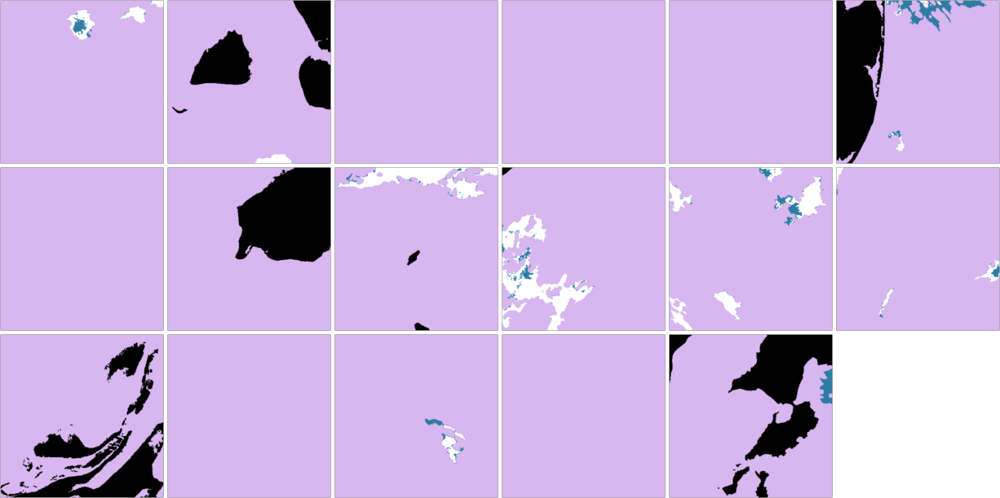

In [187]:
no_ice_idx = test_cases.info[test_cases.info.visible_sea_ice.=="no", :lookup_index]
mosaicview(visualize_results.(
        ift_cloudmask[no_ice_idx], 
        land_masks[no_ice_idx],
        ift_icemasks[no_ice_idx]),
    nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)

In [192]:
ice_pixels = sum_mask.(ift_icemasks[no_ice_idx])
true_cloud_pixels = sum_mask.(ift_cloudmask[no_ice_idx]) .+ ice_pixels
sum(ice_pixels) / sum(true_cloud_pixels)

0.01767182271701275

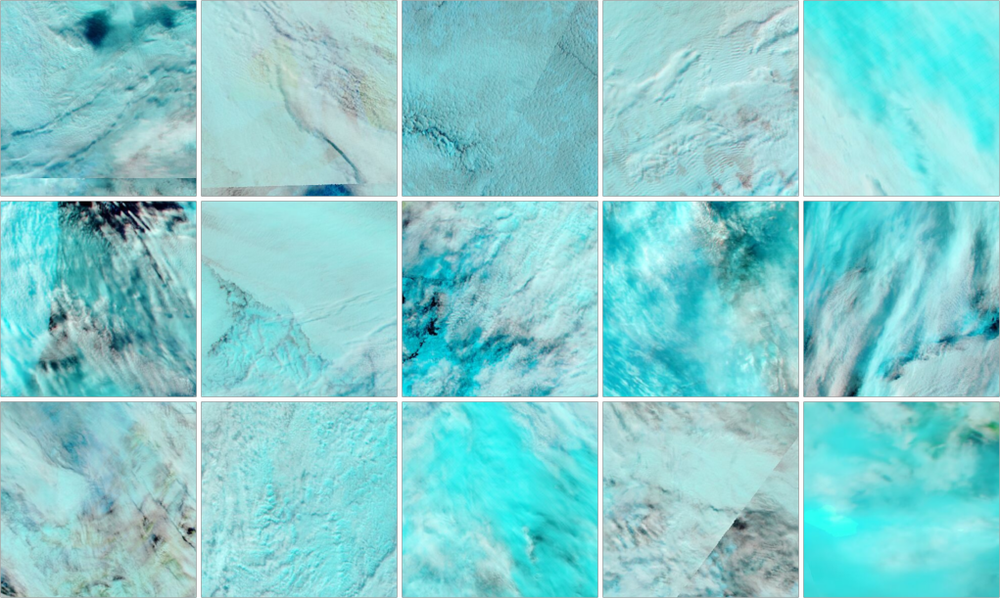

In [394]:
mosaicview(fc_imgs[cloud_idx],
    nrow=3, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)

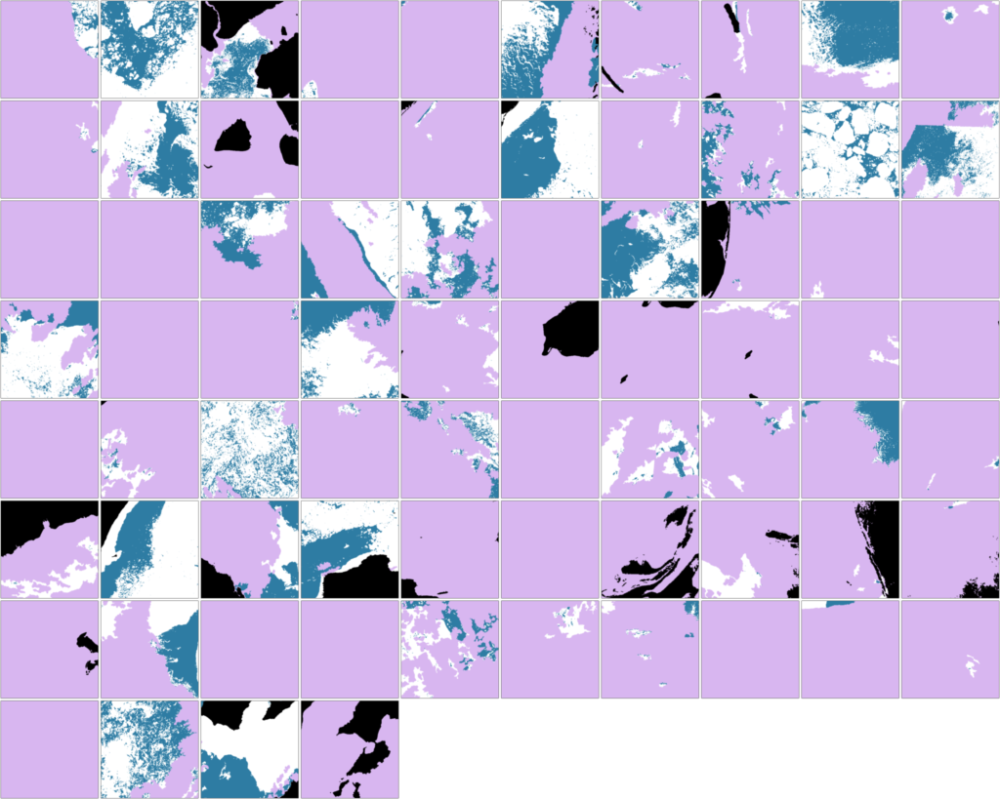

In [128]:
img_classified = mosaicview(visualize_results.(
        ift_cloudmask, 
        land_masks,
        ift_icemasks),
    nrow=8, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
save("../figures/classification_results_test_cases.png", img_classified)
img_classified

Validation: When floes are covered by the mask, what do the metadata say?

In [193]:
sea_ice_floe_cases = subset(coalesce.(test_cases.info, 0), :maximum_floe_size => r -> r .> 64);
df_list = []
for df_row in eachrow(sea_ice_floe_cases)
    idx = df_row.lookup_index
    img = SegmentedImage(fc_imgs[idx], label_components(sea_ice_floes[idx]))
    mean_colors = segment_mean(img)
    df = regionprops_table(img; properties=[:label, :bbox, :centroid, :area])
    df[:, :b7_mean] = [red(mean_colors[l]) for l in df[:, :label]]
    df[:, :b2_mean] = [green(mean_colors[l]) for l in df[:, :label]]
    df[:, :b1_mean] = [blue(mean_colors[l]) for l in df[:, :label]]
    df[:, :case_number] .= df_row.case_number

    # cloud fraction (MODIS)
    img = SegmentedImage(modis_cloud_masks[idx], label_components(sea_ice_floes[idx]))
    mean_fracs = segment_mean(img)
    df[:, :modis_cloud_fraction] = [mean_fracs[l] for l in df[:, :label]]
    
    img = SegmentedImage(ift_cloudmask[idx], label_components(sea_ice_floes[idx]))
    mean_fracs = segment_mean(img)
    df[:, :ift_cloud_fraction] = [mean_fracs[l] for l in df[:, :label]]
    df[:, :cloud_fraction_manual] .= df_row.cloud_fraction_manual
    df[:, :floe_obscuration] .= df_row.floe_obscuration

    push!(df_list, df)
end
    
df_all = reduce(vcat, df_list)
# TODO: Add cloud fraction
# TODO: Figure with floes sized by area, colored by the cloud fraction
nothing

Analysis of the floe-wise data. What can we say about cloud fraction in the two datasets? Similar enough?


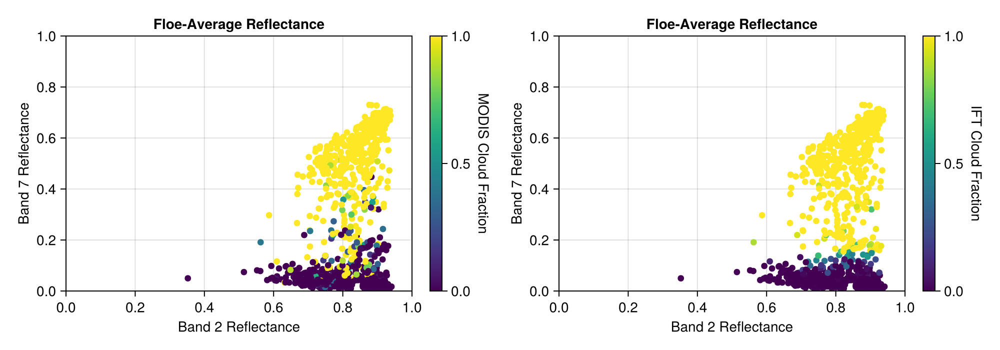

In [194]:
f = Figure(size=(1000, 350))
ax1 = CairoMakie.Axis(f[1, 1], title="Floe-Average Reflectance",
    ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))

a = scatter!(ax1, df_all[:, :b2_mean], df_all[:, :b7_mean], color=df_all[:, :modis_cloud_fraction], colormap=:viridis)
Colorbar(f[1, 2], a; label="MODIS Cloud Fraction", labelrotation=-pi/2)

ax1 = CairoMakie.Axis(f[1, 3], title="Floe-Average Reflectance",
    ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))

a = scatter!(ax1, df_all[:, :b2_mean], df_all[:, :b7_mean], color=df_all[:, :ift_cloud_fraction], colormap=:viridis)
Colorbar(f[1, 4], a; label="IFT Cloud Fraction", labelrotation=-pi/2)

current_figure()

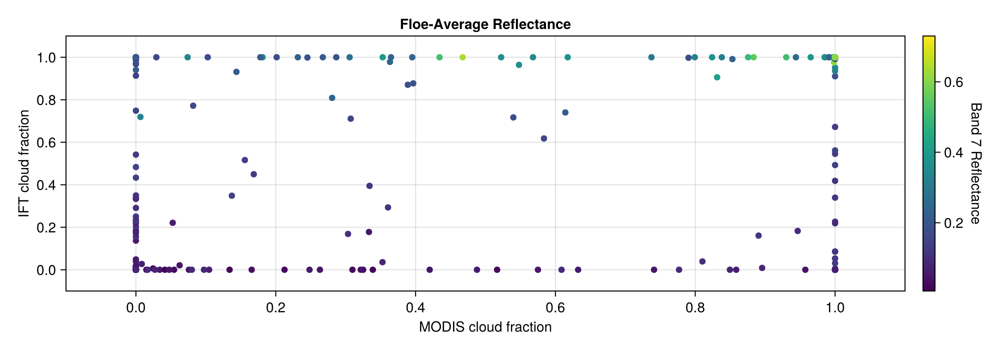

In [195]:
f = Figure(size=(1000, 350))
ax1 = CairoMakie.Axis(f[1, 1], title="Floe-Average Reflectance",
    ylabel="IFT cloud fraction", xlabel="MODIS cloud fraction",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(-0.1, 1.1, -0.1, 1.1))

a = scatter!(ax1, df_all[:, :modis_cloud_fraction], df_all[:, :ift_cloud_fraction], color=df_all[:, :b7_mean], colormap=:viridis)
Colorbar(f[1, 2], a; label="Band 7 Reflectance", labelrotation=-pi/2)
current_figure()

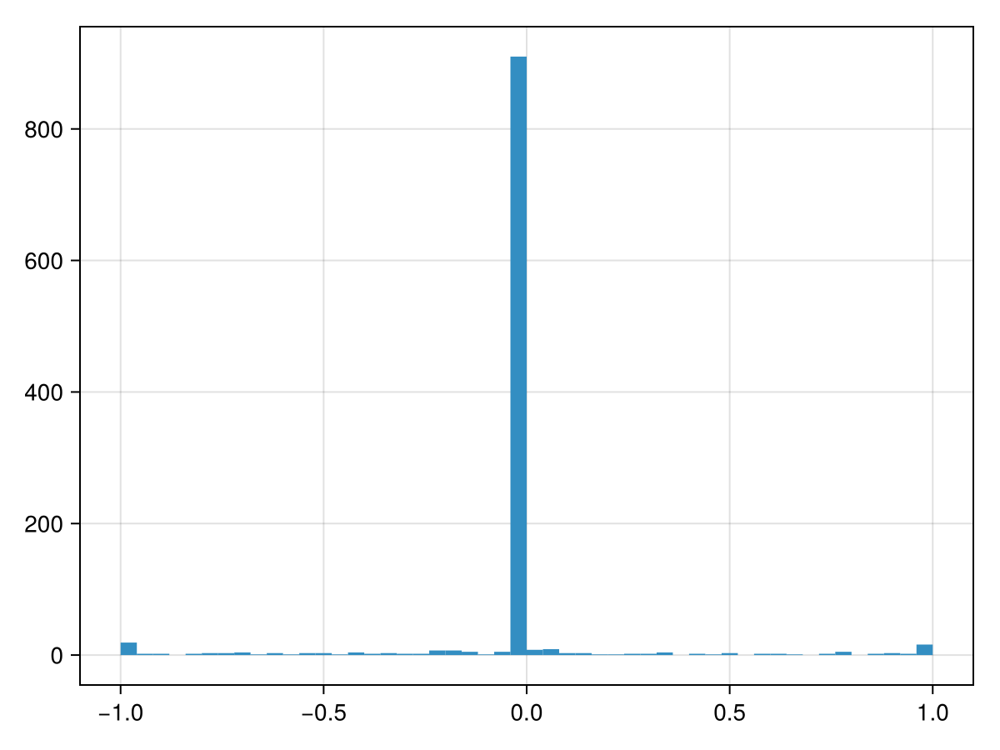

In [196]:
hist(df_all[:, :modis_cloud_fraction] .- df_all[:, :ift_cloud_fraction], bins=50)

In [197]:
combine(groupby(df_all, :floe_obscuration), nrow)

Row,floe_obscuration,nrow
,String,Int64
1,heavy,110
2,none,249
3,moderate,427
4,light,283


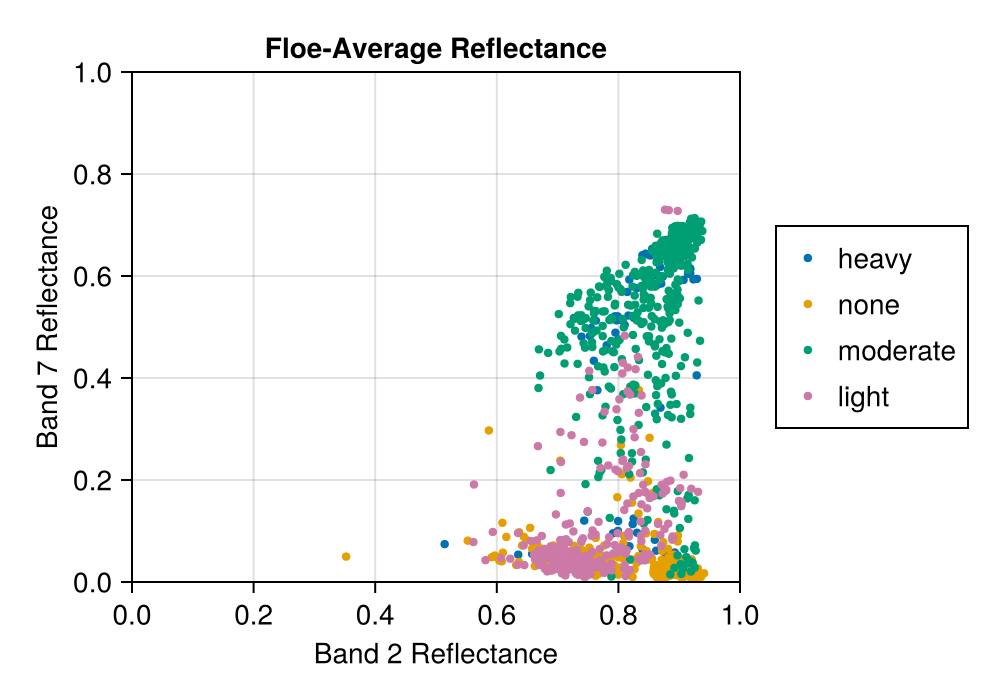

In [198]:
f = Figure(size=(500, 350))

ax1 = CairoMakie.Axis(f[1, 1], title="Floe-Average Reflectance",
    ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))

for gdf in groupby(df_all, :floe_obscuration)
    scatter!(ax1, gdf[:, :b2_mean], gdf[:, :b7_mean], label=gdf[1, :floe_obscuration], markersize=6)
end
Legend(f[1, 2], ax1)
current_figure()

heavy 0.74
none 0.06
moderate 0.95
light 0.26


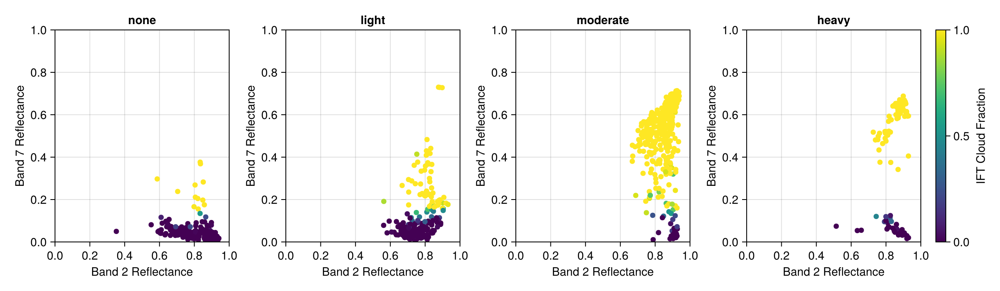

In [199]:
f = Figure(size=(1200, 350))

order = Dict("none"=>1, "light"=>2, "moderate"=>3, "heavy"=>4)

for gdf in groupby(df_all, :floe_obscuration)
    ctype = gdf[1, :floe_obscuration]
    idx = order[ctype]
    ax = CairoMakie.Axis(f[1, idx], title=ctype,
    ylabel="Band 7 Reflectance", xlabel="Band 2 Reflectance",
    yticks=0:0.2:1, xticks=0:0.2:1, limits=(0, 1, 0, 1))
    scatter!(ax, gdf[:, :b2_mean], gdf[:, :b7_mean], color=gdf[:, :ift_cloud_fraction],
        colormap=:viridis, colorrange=(0, 1))
    println(gdf[1, :floe_obscuration], " ", round(mean(gdf[:, :ift_cloud_fraction] .> 0.2), digits=2))
end
Colorbar(f[1, 5], colormap=:viridis, colorrange=(0, 1), label="IFT Cloud Fraction")
current_figure()

In [200]:
combine(groupby(df_all[df_all.floe_obscuration .== "heavy" .&& df_all.ift_cloud_fraction .< 0.5, :], :case_number), nrow)

Row,case_number,nrow
,Int64,Int64
1,13,19
2,15,3
3,51,1
4,144,10


In [201]:
test_cases.info[test_cases.info.case_number .== 13, :lookup_index]

1-element Vector{Int64}:
 1

In [202]:
# Cases with some low cloud cover but "heavy" obscuration
# Case 3: "heavy" isn't really right

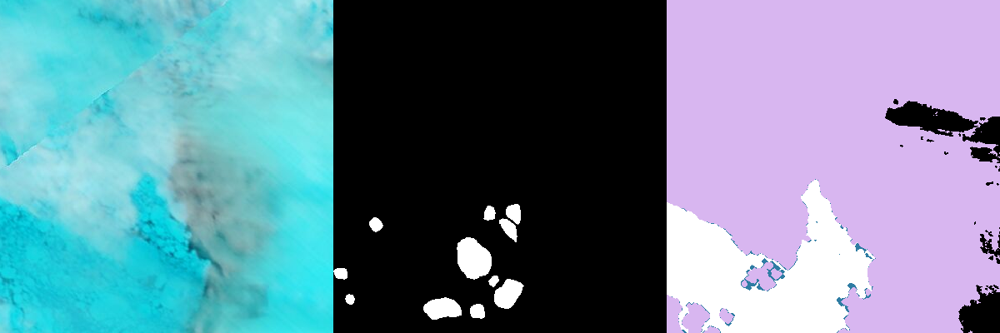

In [203]:
index = 58 # case 144
mosaicview(
    fc_imgs[index],
    Gray.(sea_ice_floes[index]),
    visualize_results(ift_cloudmask[index], land_masks[index], ift_icemasks[index]),
    nrow=1)

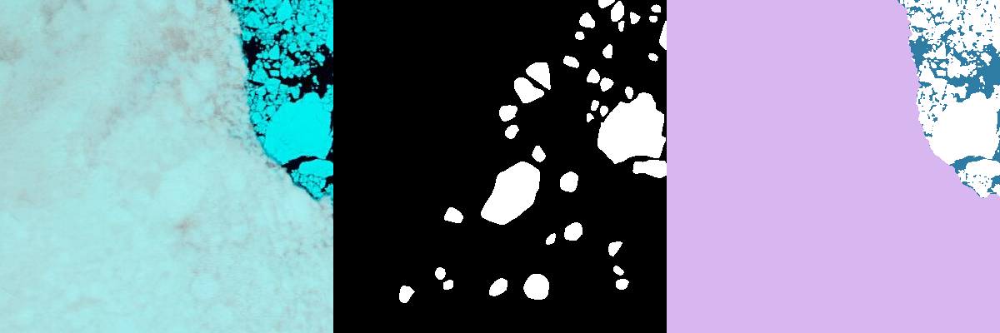

In [347]:
index = 1 # case 13
mosaicview(
    fc_imgs[index],
    Gray.(sea_ice_floes[index]),
    visualize_results(ift_cloudmask[index], land_masks[index], ift_icemasks[index]),
    nrow=1)

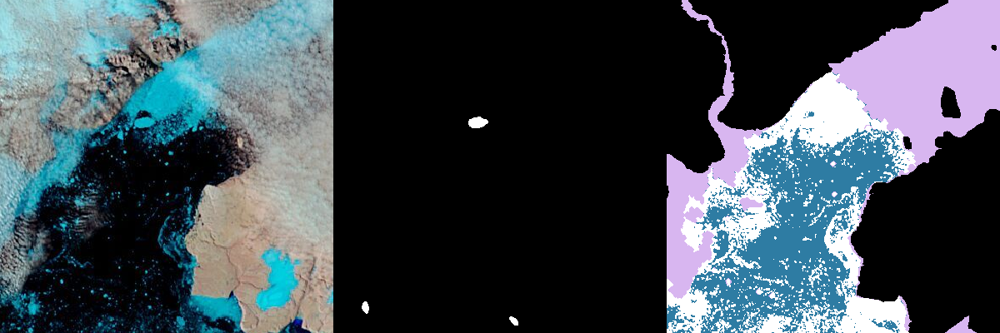

In [204]:
index = 3 # case 15
mosaicview(
    fc_imgs[index],
    Gray.(sea_ice_floes[index]),
    visualize_results(ift_cloudmask[index], land_masks[index], ift_icemasks[index]),
    nrow=1)

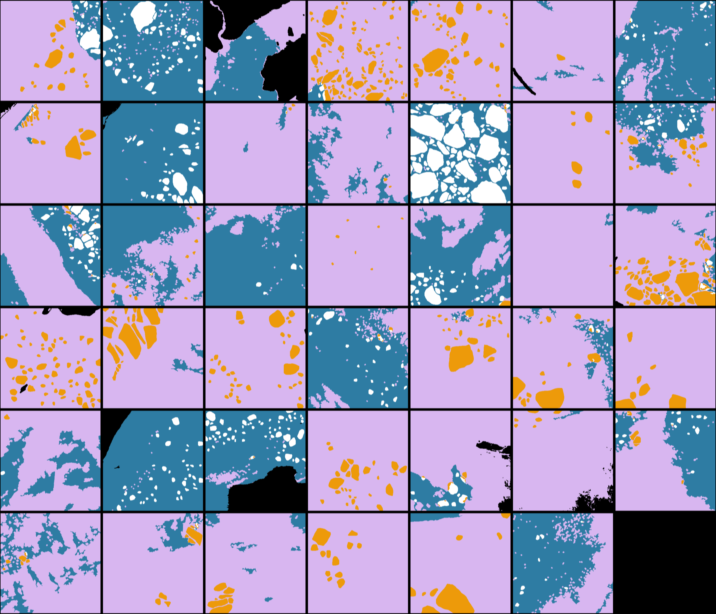

In [205]:
idx = sea_ice_floe_cases[:, :lookup_index]
img_comparison_julia = mosaicview(visualize_ice_under_cloud.(sea_ice_floes[idx],
        ift_cloudmask[idx], land_masks[idx]), nrow=6, npad=10, fillvalue=RGBA(0,0,0,0), rowmajor=true)
img_comparison_julia

In [361]:
length(idx)

41